# RQ19 — Candidate prioritization as a biological demonstration

## Scientific question

**Can the frozen PU benchmark identify unlabeled proteins that remain candidate-like across robust representations, learning paradigms, base learners, and R/S regimes, while avoiding the claim that high model scores constitute biological validation?**

RQ19 is intentionally a **demonstration of prioritization**, not a second mining paper.

The output is a small, auditable set of proteins:

> **prioritized for experimental characterization**

not:

> “computationally validated lytic enzymes”.

No docking, mechanistic assignment, structural storytelling, or motif mining is required for this RQ.


## Evidence hierarchy

The roadmap proposes candidate support from:

```text
high predictive/ranking support
+
consensus across robust models
+
persistence across R/S
+
agreement between PU methods
+
agreement T6/T30
+
physicochemical support
+
latent-space support
+
nontrivial sequence relatedness
```

RQ19 operationalizes this in **two stages**.

### Stage A — primary predictive consensus

The primary discovery universe is `pu_broad`, because it contains the widest unresolved background.

Only rank information is combined across models. Raw probability/score values are **not averaged across model families**, because RQ12 showed that score scales can differ materially, particularly under Elkan–Noto.

Primary consensus uses:

- ESM2-T6 and ESM2-T30;
- naive P-vs-U and BaggingPU;
- LR and XGB;
- all 16 R×S cells;
- within-experiment U percentiles;
- tie-aware top-5% and top-1% membership;
- persistence across R/S;
- agreement between representations, methods, and learners.

Elkan–Noto is retained as an **agreement diagnostic**, not as a primary consensus vote, because its upper score range can contain clipping/tie plateaus.

### Stage B — characterization support

The predictive shortlist is annotated, where the retained artifacts make this possible, with:

- conservative-U persistence for shared candidate entities;
- physicochemical compatibility with known positives using Roxy features;
- T30 latent-space proximity/support relative to known positives;
- exact sequence duplication checks;
- optional sequence-relatedness screening.

Missing optional artifacts are reported as **not estimable** and do not invalidate Stage A.


## Why percentile/rank aggregation is used

For an unlabeled protein \(i\) scored in experiment \(e\):

\[
p_{i,e}
=
\frac{
\#\{u\in U_e:s_u\le s_{i,e}\}
}{
|U_e|
}.
\]

Thus \(p_{i,e}\in(0,1]\) describes the candidate's position **within the U distribution of that exact model**.

Tie-inclusive candidate tails are defined as:

\[
\mathrm{Top5}_e=
\{i:s_i\ge Q_{0.95}(s_U)\}
\]

and analogously for Top1 at \(Q_{0.99}\).

This avoids:

- comparing incompatible raw score scales;
- arbitrary tie breaking at tail boundaries;
- interpreting Elkan–Noto clipping as extra evidence.


## Primary eligibility contract

A protein can enter the main predictive ranking only if, within the broad-U primary model set:

- it is observed in at least **4 distinct R×S cells**;
- it has evidence under both **T6 and T30**;
- it has evidence under both **naive and BaggingPU**;
- it has evidence under both **LR and XGB**;
- it is observed under at least **2 distinct R levels**;
- it is observed under at least **2 distinct S levels**.

These are coverage requirements, not biological filters.

They prevent a protein that appears in only one favorable outer-test partition from outranking a candidate supported repeatedly across the factorial.


## Predictive consensus components

For every eligible broad-U entity we compute:

1. **Median percentile support**
   \[
   C_{\mathrm{rank}}
   =
   \mathrm{median}(p_{i,e})
   \]

2. **Top-5 persistence**
   \[
   C_{\mathrm{tail}}
   =
   \frac{\#\{e:i\in\mathrm{Top5}_e\}}
   {\#\{e:i\text{ observed}\}}
   \]

3. **R/S persistence**
   - fraction of observed R×S cells in which the candidate reaches the top 5%;
   - explicit top-5 support at `S30`;
   - explicit top-5 support at `R30`.

4. **Representation consensus**
   - T6 median percentile;
   - T30 median percentile;
   - minimum of the two.

5. **Paradigm consensus**
   - naive median percentile;
   - BaggingPU median percentile;
   - minimum of the two.

6. **Learner consensus**
   - LR median percentile;
   - XGB median percentile;
   - minimum of the two.

The primary consensus score is an **equal-weight descriptive aggregation**:

\[
C =
\mathrm{mean}
(
C_{\mathrm{rank}},
C_{\mathrm{tail}},
C_{\mathrm{rep}},
C_{\mathrm{method}},
C_{\mathrm{learner}},
C_{\mathrm{RS}}
)
\]

where every component is already on \([0,1]\).

`C` is a prioritization index, **not a calibrated probability of lytic function**.


In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 300)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

PRIMARY_TASK = "pu_broad"
BRIDGE_TASK = "pu_conservative"

PRIMARY_REPS = [
    "esm2_t6_8m",
    "esm2_t30_150m",
]

PRIMARY_METHODS = [
    "naive",
    "baggingpu",
]

DIAGNOSTIC_METHODS = [
    "elkan_noto",
]

EXPECTED_ALGS = ["LR", "XGB"]

TOP5_Q = 0.95
TOP1_Q = 0.99

MIN_DISTINCT_RS = 4
MIN_DISTINCT_R = 2
MIN_DISTINCT_S = 2

PREDICTIVE_SHORTLIST_N = 100
DEMONSTRATION_N = 20

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_pu/stage12b2").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
            and (candidate / "data").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "PU Stage12 outputs and data/."
    )

ROOT = find_project_root()

PU_STAGE12B2 = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"

REP_ROOT = ROOT / "data/representations"

RQ19_CACHE = ROOT / "results/analysis_candidates/rq19"
RQ19_CACHE.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ19_CACHE:", RQ19_CACHE)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ19_CACHE: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19


# 1. Validate frozen PU benchmark


In [2]:
manifest_path = (
    PU_STAGE12B2
    / "stage12b2_manifest.json"
)

if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

manifest = json.loads(
    manifest_path.read_text()
)

if manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Stage12B2 status={manifest.get('status')}; "
        "RQ19 requires a frozen PASS benchmark."
    )

registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

required_registry = {
    "experiment_id",
    "task",
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    "path",
}

missing = (
    required_registry
    - set(registry.columns)
)

if missing:
    raise KeyError(
        f"PU registry missing columns: {sorted(missing)}"
    )

assert len(registry) == 768
assert set(registry["task"]) == {
    "pu_conservative",
    "pu_broad",
}
assert set(registry["method"]) == {
    "naive",
    "baggingpu",
    "elkan_noto",
}
assert set(registry["algorithm"]) == set(
    EXPECTED_ALGS
)

coverage = (
    registry.groupby(
        [
            "task",
            "R",
            "S",
            "representation",
            "method",
            "algorithm",
        ]
    )
    .size()
)

assert len(coverage) == 768
assert coverage.eq(1).all()

print("PASS — frozen PU factorial:", len(registry))
display(
    registry.groupby(
        ["task", "method"]
    ).size().unstack()
)


PASS — frozen PU factorial: 768


method,baggingpu,elkan_noto,naive
task,,,
pu_broad,128,128,128
pu_conservative,128,128,128


# 2. Identity and score utilities


In [3]:
HEX64_RE = re.compile(
    r"^[0-9a-fA-F]{64}$"
)

def clean_text(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
        .astype(str)
    )

def normalize_sequence(series):
    return (
        clean_text(series)
        .str.replace(
            r"\s+",
            "",
            regex=True,
        )
        .str.upper()
    )

def detect_score_col(df):
    for c in [
        "score_positive",
        "score",
        "corrected_score",
        "probability",
        "proba_positive",
    ]:
        if c in df.columns:
            x = pd.to_numeric(
                df[c],
                errors="coerce",
            )
            if x.notna().any():
                return c

    raise KeyError(
        "No usable score column. "
        f"Columns: {list(df.columns)}"
    )

def attach_sequence_key(df):
    out = df.copy()

    if "sequence_sha256" in out.columns:
        key = (
            clean_text(
                out["sequence_sha256"]
            )
            .str.lower()
        )

        if key.ne("").all():
            out["sequence_key"] = key
            out["sequence_key_source"] = (
                "sequence_sha256"
            )
            return out

    for c in [
        "sequence",
        "sequence_norm",
        "seq",
    ]:
        if c in out.columns:
            seq = normalize_sequence(
                out[c]
            )

            if seq.ne("").all():
                out["sequence_key"] = seq.map(
                    lambda s: hashlib.sha256(
                        s.encode("utf-8")
                    ).hexdigest()
                )
                out[
                    "sequence_key_source"
                ] = "derived_sequence_sha256"
                return out

    if "sequence_uid" in out.columns:
        uid = clean_text(
            out["sequence_uid"]
        )

        if uid.ne("").all():
            out["sequence_key"] = uid
            out[
                "sequence_key_source"
            ] = "sequence_uid"
            return out

    if "entity_id" in out.columns:
        eid = clean_text(
            out["entity_id"]
        )

        if eid.ne("").all():
            out["sequence_key"] = eid
            out[
                "sequence_key_source"
            ] = "entity_id_fallback"
            return out

    raise RuntimeError(
        "Could not construct stable entity identity. "
        f"Columns: {list(out.columns)}"
    )

def percentile_against_self(scores):
    scores = np.asarray(
        scores,
        dtype=float,
    )

    ordered = np.sort(scores)

    return (
        np.searchsorted(
            ordered,
            scores,
            side="right",
        )
        / len(ordered)
    )

def tie_aware_tail(scores, q):
    scores = np.asarray(
        scores,
        dtype=float,
    )

    threshold = np.quantile(
        scores,
        q,
    )

    return (
        scores >= threshold,
        float(threshold),
    )

def safe_bool_mean(values):
    x = pd.Series(values).dropna()

    if len(x) == 0:
        return np.nan

    return float(
        x.astype(bool).mean()
    )


# 3. Mandatory synthetic self-test of candidate aggregation logic


In [4]:
synthetic_scores = np.array(
    [0.1, 0.2, 0.2, 0.7, 0.9, 0.9]
)

pct = percentile_against_self(
    synthetic_scores
)

assert np.isclose(
    pct[-1],
    1.0,
)
assert np.isclose(
    pct[1],
    3 / 6,
)
assert np.isclose(
    pct[2],
    3 / 6,
)

top5, q95 = tie_aware_tail(
    synthetic_scores,
    0.95,
)

assert top5.sum() == 2
assert np.isclose(q95, 0.9)

print(
    "PASS — rank percentile and tie-aware tail self-test."
)


PASS — rank percentile and tie-aware tail self-test.


# 4. Load only discovery-relevant PU score vectors


In [5]:
analysis_registry = registry[
    registry["representation"].isin(
        PRIMARY_REPS
    )
    & registry["task"].isin(
        [
            PRIMARY_TASK,
            BRIDGE_TASK,
        ]
    )
].copy()

print(
    "Discovery-relevant score files:",
    len(analysis_registry),
)

display(
    analysis_registry.groupby(
        [
            "task",
            "representation",
            "method",
            "algorithm",
        ]
    ).size()
)


Discovery-relevant score files: 384


task             representation  method      algorithm
pu_broad         esm2_t30_150m   baggingpu   LR           16
                                             XGB          16
                                 elkan_noto  LR           16
                                             XGB          16
                                 naive       LR           16
                                             XGB          16
                 esm2_t6_8m      baggingpu   LR           16
                                             XGB          16
                                 elkan_noto  LR           16
                                             XGB          16
                                 naive       LR           16
                                             XGB          16
pu_conservative  esm2_t30_150m   baggingpu   LR           16
                                             XGB          16
                                 elkan_noto  LR           16
                              

In [6]:
score_rows = []
score_schema_rows = []

for rec in analysis_registry.itertuples(
    index=False
):
    score_path = (
        Path(rec.path)
        / "outer_test_scores.parquet"
    )

    if not score_path.is_file():
        raise FileNotFoundError(
            score_path
        )

    df = pd.read_parquet(
        score_path
    )

    if "observed_role" not in df.columns:
        raise KeyError(
            f"{score_path}: missing observed_role"
        )

    df = attach_sequence_key(df)
    score_col = detect_score_col(df)

    roles = (
        df["observed_role"]
        .astype(str)
        .str.upper()
    )

    scores = pd.to_numeric(
        df[score_col],
        errors="coerce",
    )

    valid = (
        scores.notna()
        & roles.isin(["P", "U"])
    )

    x = df.loc[
        valid,
        [
            c
            for c in [
                "sequence_key",
                "sequence_key_source",
                "entity_id",
                "sequence_uid",
                "sequence_sha256",
                "sequence",
                "sequence_norm",
                "seq",
                "canonical_state",
                "source_stratum",
                "observed_role",
            ]
            if c in df.columns
        ],
    ].copy()

    x["observed_role"] = (
        roles.loc[valid]
        .astype(str)
        .to_numpy()
    )

    x["score"] = (
        scores.loc[valid]
        .astype(float)
        .to_numpy()
    )

    U_mask = x[
        "observed_role"
    ].eq("U")

    if U_mask.any():
        U_scores = x.loc[
            U_mask,
            "score",
        ].to_numpy(float)

        U_pct = percentile_against_self(
            U_scores
        )

        top5, q95 = tie_aware_tail(
            U_scores,
            TOP5_Q,
        )

        top1, q99 = tie_aware_tail(
            U_scores,
            TOP1_Q,
        )

        x.loc[
            U_mask,
            "U_percentile",
        ] = U_pct

        x.loc[
            U_mask,
            "top5_tieaware",
        ] = top5

        x.loc[
            U_mask,
            "top1_tieaware",
        ] = top1
    else:
        q95 = np.nan
        q99 = np.nan

    x["task"] = rec.task
    x["R"] = int(rec.R)
    x["S"] = int(rec.S)
    x[
        "representation"
    ] = rec.representation
    x["method"] = rec.method
    x["algorithm"] = rec.algorithm
    x[
        "experiment_id"
    ] = rec.experiment_id

    score_rows.append(x)

    score_schema_rows.append({
        "experiment_id": rec.experiment_id,
        "task": rec.task,
        "R": int(rec.R),
        "S": int(rec.S),
        "representation": rec.representation,
        "method": rec.method,
        "algorithm": rec.algorithm,
        "score_column": score_col,
        "sequence_key_source": (
            x[
                "sequence_key_source"
            ].iloc[0]
            if len(x)
            else np.nan
        ),
        "n_rows": len(x),
        "n_P": int(
            x[
                "observed_role"
            ].eq("P").sum()
        ),
        "n_U": int(
            x[
                "observed_role"
            ].eq("U").sum()
        ),
        "U_q95": q95,
        "U_q99": q99,
    })

scores_long = pd.concat(
    score_rows,
    ignore_index=True,
)

score_schema_audit = pd.DataFrame(
    score_schema_rows
)

print(
    "Loaded score rows:",
    len(scores_long),
)

display(
    score_schema_audit.groupby(
        [
            "task",
            "representation",
            "method",
        ]
    )
    .agg(
        n_files=(
            "experiment_id",
            "size",
        ),
        median_U=(
            "n_U",
            "median",
        ),
        median_P=(
            "n_P",
            "median",
        ),
    )
    .reset_index()
)


Loaded score rows: 16082472


,task,representation,method,n_files,median_U,median_P
0,pu_broad,esm2_t30_150m,baggingpu,32,46331.0,903.5
1,pu_broad,esm2_t30_150m,elkan_noto,32,46331.0,903.5
2,pu_broad,esm2_t30_150m,naive,32,46331.0,903.5
3,pu_broad,esm2_t6_8m,baggingpu,32,46331.0,903.5
4,pu_broad,esm2_t6_8m,elkan_noto,32,46331.0,903.5
5,pu_broad,esm2_t6_8m,naive,32,46331.0,903.5
6,pu_conservative,esm2_t30_150m,baggingpu,32,32973.5,839.5
7,pu_conservative,esm2_t30_150m,elkan_noto,32,32973.5,839.5
8,pu_conservative,esm2_t30_150m,naive,32,32973.5,839.5
9,pu_conservative,esm2_t6_8m,baggingpu,32,32973.5,839.5


This is the main heavy I/O step of RQ19.

Every later candidate statistic is computed from this single long score table rather than repeatedly reopening the 384 selected score files.


# 5. Entity metadata audit


In [7]:
metadata_cols = [
    c
    for c in [
        "entity_id",
        "sequence_uid",
        "sequence_sha256",
        "sequence",
        "sequence_norm",
        "seq",
        "canonical_state",
        "source_stratum",
    ]
    if c in scores_long.columns
]

entity_metadata_candidates = (
    scores_long[
        [
            "sequence_key",
            "task",
            "observed_role",
            *metadata_cols,
        ]
    ]
    .drop_duplicates()
)

metadata_conflicts = []

for col in metadata_cols:
    nuniq = (
        entity_metadata_candidates.groupby(
            "sequence_key"
        )[col]
        .nunique(dropna=True)
    )

    bad = nuniq[
        nuniq > 1
    ]

    metadata_conflicts.append({
        "field": col,
        "n_entities_with_conflict": int(
            len(bad)
        ),
    })

metadata_conflict_audit = pd.DataFrame(
    metadata_conflicts
)

display(metadata_conflict_audit)


,field,n_entities_with_conflict
0,entity_id,0
1,sequence_uid,0


# 6. Primary broad-U evidence table


In [8]:
primary_evidence = scores_long[
    scores_long["task"].eq(
        PRIMARY_TASK
    )
    & scores_long[
        "observed_role"
    ].eq("U")
    & scores_long[
        "representation"
    ].isin(PRIMARY_REPS)
    & scores_long[
        "method"
    ].isin(PRIMARY_METHODS)
    & scores_long[
        "algorithm"
    ].isin(EXPECTED_ALGS)
].copy()

if len(primary_evidence) == 0:
    raise RuntimeError(
        "No broad-U primary candidate evidence was found."
    )

primary_evidence[
    "rs_cell"
] = (
    "R"
    + primary_evidence["R"].astype(str)
    + "_S"
    + primary_evidence["S"].astype(str)
)

print(
    "Primary broad-U evidence rows:",
    len(primary_evidence),
)
print(
    "Unique broad-U entities:",
    primary_evidence[
        "sequence_key"
    ].nunique(),
)


Primary broad-U evidence rows: 6126048
Unique broad-U entities: 209972


# 7. Candidate-level coverage and persistence


In [9]:
base_candidate = (
    primary_evidence.groupby(
        "sequence_key"
    )
    .agg(
        n_observations=(
            "U_percentile",
            "count",
        ),
        n_distinct_rs=(
            "rs_cell",
            "nunique",
        ),
        n_distinct_R=(
            "R",
            "nunique",
        ),
        n_distinct_S=(
            "S",
            "nunique",
        ),
        n_representations=(
            "representation",
            "nunique",
        ),
        n_methods=(
            "method",
            "nunique",
        ),
        n_algorithms=(
            "algorithm",
            "nunique",
        ),
        median_U_percentile=(
            "U_percentile",
            "median",
        ),
        mean_U_percentile=(
            "U_percentile",
            "mean",
        ),
        q25_U_percentile=(
            "U_percentile",
            lambda x: x.quantile(0.25),
        ),
        min_U_percentile=(
            "U_percentile",
            "min",
        ),
        top5_frequency=(
            "top5_tieaware",
            "mean",
        ),
        top1_frequency=(
            "top1_tieaware",
            "mean",
        ),
    )
    .reset_index()
)

eligibility = (
    base_candidate[
        "n_distinct_rs"
    ].ge(MIN_DISTINCT_RS)
    & base_candidate[
        "n_distinct_R"
    ].ge(MIN_DISTINCT_R)
    & base_candidate[
        "n_distinct_S"
    ].ge(MIN_DISTINCT_S)
    & base_candidate[
        "n_representations"
    ].eq(2)
    & base_candidate[
        "n_methods"
    ].eq(2)
    & base_candidate[
        "n_algorithms"
    ].eq(2)
)

base_candidate[
    "eligible_primary"
] = eligibility

print(
    "Eligible candidates:",
    int(eligibility.sum()),
    "/",
    len(base_candidate),
)

display(
    base_candidate[
        [
            "n_observations",
            "n_distinct_rs",
            "n_distinct_R",
            "n_distinct_S",
        ]
    ].describe()
)


Eligible candidates: 101370 / 209972


,n_observations,n_distinct_rs,n_distinct_R,n_distinct_S
count,209972.000000,209972.000000,209972.000000,209972.000000
mean,29.175547,3.646943,2.308546,2.562418
std,16.080222,2.010028,1.073215,1.015205
min,8.000000,1.000000,1.000000,1.000000
25%,16.000000,2.000000,1.000000,2.000000
50%,24.000000,3.000000,2.000000,3.000000
75%,40.000000,5.000000,3.000000,3.000000
max,104.000000,13.000000,4.000000,4.000000


# 8. Representation, paradigm, and learner consensus


In [10]:
def median_by_axis(
    frame,
    axis,
    prefix,
):
    wide = (
        frame.groupby(
            [
                "sequence_key",
                axis,
            ]
        )["U_percentile"]
        .median()
        .unstack(axis)
    )

    wide = wide.rename(
        columns={
            c: f"{prefix}_{c}_median_percentile"
            for c in wide.columns
        }
    )

    return (
        wide.reset_index()
    )

rep_support = median_by_axis(
    primary_evidence,
    "representation",
    "rep",
)

method_support = median_by_axis(
    primary_evidence,
    "method",
    "method",
)

algorithm_support = median_by_axis(
    primary_evidence,
    "algorithm",
    "alg",
)

candidate = (
    base_candidate
    .merge(
        rep_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        method_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        algorithm_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

T6_COL = (
    "rep_esm2_t6_8m_median_percentile"
)
T30_COL = (
    "rep_esm2_t30_150m_median_percentile"
)
NAIVE_COL = (
    "method_naive_median_percentile"
)
BAG_COL = (
    "method_baggingpu_median_percentile"
)
LR_COL = (
    "alg_LR_median_percentile"
)
XGB_COL = (
    "alg_XGB_median_percentile"
)

for col in [
    T6_COL,
    T30_COL,
    NAIVE_COL,
    BAG_COL,
    LR_COL,
    XGB_COL,
]:
    if col not in candidate.columns:
        candidate[col] = np.nan

candidate[
    "representation_consensus"
] = candidate[
    [T6_COL, T30_COL]
].min(axis=1)

candidate[
    "method_consensus"
] = candidate[
    [NAIVE_COL, BAG_COL]
].min(axis=1)

candidate[
    "learner_consensus"
] = candidate[
    [LR_COL, XGB_COL]
].min(axis=1)

candidate[
    "T30_minus_T6_candidate_percentile"
] = (
    candidate[T30_COL]
    - candidate[T6_COL]
)

candidate[
    "Bagging_minus_naive_candidate_percentile"
] = (
    candidate[BAG_COL]
    - candidate[NAIVE_COL]
)

candidate[
    "XGB_minus_LR_candidate_percentile"
] = (
    candidate[XGB_COL]
    - candidate[LR_COL]
)

display(
    candidate[
        [
            "representation_consensus",
            "method_consensus",
            "learner_consensus",
            "T30_minus_T6_candidate_percentile",
            "Bagging_minus_naive_candidate_percentile",
        ]
    ].describe()
)


,representation_consensus,method_consensus,learner_consensus,T30_minus_T6_candidate_percentile,Bagging_minus_naive_candidate_percentile
count,209972.000000,209972.000000,209972.000000,209972.000000,209972.000000
mean,0.418896,0.465413,0.444935,0.000868,0.003362
std,0.255929,0.259869,0.259648,0.227947,0.115764
min,0.000073,0.001570,0.000276,-0.918760,-0.546424
25%,0.202981,0.246106,0.224656,-0.137217,-0.067632
50%,0.386219,0.446620,0.423276,0.003433,-0.005365
75%,0.613110,0.672834,0.649165,0.140657,0.058924
max,0.999971,1.000000,0.999974,0.924487,0.763921


# 9. Explicit R/S persistence and strict-regime support


In [11]:
rs_entity = (
    primary_evidence.groupby(
        [
            "sequence_key",
            "R",
            "S",
        ]
    )
    .agg(
        rs_median_percentile=(
            "U_percentile",
            "median",
        ),
        rs_top5=(
            "top5_tieaware",
            "mean",
        ),
        rs_top1=(
            "top1_tieaware",
            "mean",
        ),
    )
    .reset_index()
)

rs_entity[
    "rs_top5_majority"
] = (
    rs_entity[
        "rs_top5"
    ] >= 0.5
)

rs_summary = (
    rs_entity.groupby(
        "sequence_key"
    )
    .agg(
        rs_top5_persistence=(
            "rs_top5_majority",
            "mean",
        ),
        rs_median_percentile=(
            "rs_median_percentile",
            "median",
        ),
        worst_rs_percentile=(
            "rs_median_percentile",
            "min",
        ),
    )
    .reset_index()
)

strict_S = (
    rs_entity[
        rs_entity["S"].eq(30)
    ]
    .groupby(
        "sequence_key"
    )
    .agg(
        S30_median_percentile=(
            "rs_median_percentile",
            "median",
        ),
        S30_top5_persistence=(
            "rs_top5_majority",
            "mean",
        ),
        n_S30_R_levels=(
            "R",
            "nunique",
        ),
    )
    .reset_index()
)

strict_R = (
    rs_entity[
        rs_entity["R"].eq(30)
    ]
    .groupby(
        "sequence_key"
    )
    .agg(
        R30_median_percentile=(
            "rs_median_percentile",
            "median",
        ),
        R30_top5_persistence=(
            "rs_top5_majority",
            "mean",
        ),
        n_R30_S_levels=(
            "S",
            "nunique",
        ),
    )
    .reset_index()
)

candidate = (
    candidate
    .merge(
        rs_summary,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        strict_S,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        strict_R,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

candidate[
    "strict_regime_support"
] = (
    candidate[
        [
            "S30_median_percentile",
            "R30_median_percentile",
        ]
    ]
    .mean(axis=1)
)

candidate[
    "rs_consensus"
] = (
    candidate[
        [
            "rs_top5_persistence",
            "strict_regime_support",
        ]
    ]
    .mean(axis=1)
)


# 10. Primary predictive consensus score


In [12]:
CONSENSUS_COMPONENTS = [
    "median_U_percentile",
    "top5_frequency",
    "representation_consensus",
    "method_consensus",
    "learner_consensus",
    "rs_consensus",
]

candidate[
    "predictive_consensus_score"
] = (
    candidate[
        CONSENSUS_COMPONENTS
    ]
    .mean(
        axis=1,
        skipna=False,
    )
)

candidate[
    "predictive_consensus_min_component"
] = (
    candidate[
        CONSENSUS_COMPONENTS
    ]
    .min(
        axis=1,
        skipna=False,
    )
)

eligible = (
    candidate[
        candidate[
            "eligible_primary"
        ]
    ]
    .dropna(
        subset=[
            "predictive_consensus_score"
        ]
    )
    .copy()
)

eligible[
    "predictive_rank"
] = (
    eligible[
        "predictive_consensus_score"
    ]
    .rank(
        ascending=False,
        method="min",
    )
    .astype(int)
)

eligible = eligible.sort_values(
    [
        "predictive_consensus_score",
        "predictive_consensus_min_component",
        "top5_frequency",
        "median_U_percentile",
    ],
    ascending=False,
).reset_index(drop=True)

predictive_shortlist = (
    eligible.head(
        PREDICTIVE_SHORTLIST_N
    )
    .copy()
)

demonstration = (
    eligible.head(
        DEMONSTRATION_N
    )
    .copy()
)

display(
    eligible[
        [
            "predictive_consensus_score",
            "predictive_consensus_min_component",
            "median_U_percentile",
            "top5_frequency",
            "top1_frequency",
            "rs_top5_persistence",
            "S30_median_percentile",
            "R30_median_percentile",
            "n_distinct_rs",
        ]
    ].describe()
)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "predictive_consensus_score",
            "median_U_percentile",
            "top5_frequency",
            "top1_frequency",
            "representation_consensus",
            "method_consensus",
            "learner_consensus",
            "rs_top5_persistence",
            "S30_median_percentile",
            "R30_median_percentile",
        ]
    ]
)


,median_U_percentile,rs_top5_persistence,S30_median_percentile,R30_median_percentile,n_distinct_rs
count,101370.000000,101370.000000,84395.000000,70268.000000,101370.000000
mean,0.500250,0.042305,0.497602,0.502739,5.379461
std,0.253876,0.183400,0.254002,0.254538,1.359033
min,0.003900,0.000000,0.002721,0.001673,4.000000
25%,0.289114,0.000000,0.287239,0.293114,4.000000
50%,0.488846,0.000000,0.486543,0.494171,5.000000
75%,0.705763,0.000000,0.702570,0.708048,6.000000
max,1.000000,1.000000,1.000000,0.999985,13.000000


,predictive_rank,sequence_key,predictive_consensus_score,median_U_percentile,top5_frequency,top1_frequency,representation_consensus,method_consensus,learner_consensus,rs_top5_persistence,S30_median_percentile,R30_median_percentile
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,0.99999,1.000000,1.0,1.0,0.999971,1.000000,0.999974,1.0,1.000000,0.999985
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.999895,0.999887,1.0,1.0,0.999887,0.999820,0.999796,1.0,0.999971,0.999956
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.999872,0.999855,1.0,1.0,0.999826,0.999775,0.999827,1.0,0.999898,0.999898
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,0.999866,0.999878,1.0,1.0,0.999809,0.999818,0.999767,1.0,0.999847,NaN
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.999855,0.999829,1.0,1.0,0.999814,0.999765,0.999814,1.0,0.999773,0.999855
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.999842,0.999824,1.0,1.0,0.999810,0.999794,0.999729,1.0,0.999793,0.999796
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.999816,0.999818,1.0,1.0,0.999730,0.999766,0.999668,1.0,0.999845,0.999811
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.999801,0.999869,1.0,1.0,0.999434,0.999767,0.999811,1.0,0.999884,0.999825
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.999797,0.999796,1.0,1.0,0.999678,0.999699,0.999689,1.0,NaN,0.999840
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,0.99976,0.999827,1.0,1.0,0.999816,0.999596,0.999478,1.0,0.999852,0.999520


The primary shortlist is intentionally selected **before** physicochemical or latent-space annotation.

This preserves a clean distinction:

- predictive models nominate candidates;
- orthogonal representation/property analyses characterize how well supported or unusual those nominations are.


# 11. Consensus decomposition for top candidates


In [13]:
top_long = (
    primary_evidence[
        primary_evidence[
            "sequence_key"
        ].isin(
            demonstration[
                "sequence_key"
            ]
        )
    ]
    .copy()
)

candidate_factor_summary = (
    top_long.groupby(
        [
            "sequence_key",
            "representation",
            "method",
            "algorithm",
        ]
    )
    .agg(
        n=("U_percentile", "size"),
        median_percentile=(
            "U_percentile",
            "median",
        ),
        top5_frequency=(
            "top5_tieaware",
            "mean",
        ),
        top1_frequency=(
            "top1_tieaware",
            "mean",
        ),
    )
    .reset_index()
)

display(candidate_factor_summary)


,sequence_key,representation,method,algorithm,n,median_percentile,top5_frequency,top1_frequency
0,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t30_150m,baggingpu,LR,5,0.999984,1.0,1.0
1,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t30_150m,baggingpu,XGB,5,0.999214,1.0,1.0
2,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t30_150m,naive,LR,5,1.000000,1.0,1.0
3,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t30_150m,naive,XGB,5,0.999546,1.0,1.0
4,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t6_8m,baggingpu,LR,5,0.999862,1.0,1.0
5,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t6_8m,baggingpu,XGB,5,0.999410,1.0,1.0
6,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t6_8m,naive,LR,5,0.999803,1.0,1.0
7,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,esm2_t6_8m,naive,XGB,5,0.999913,1.0,1.0
8,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,esm2_t30_150m,baggingpu,LR,5,0.999884,1.0,1.0
9,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,esm2_t30_150m,baggingpu,XGB,5,1.000000,1.0,1.0


# 12. Candidate rank stability under leave-one-axis-out consensus


In [14]:
stability_rows = []

eligible_indexed = (
    eligible.set_index(
        "sequence_key"
    )
)

for dropped in CONSENSUS_COMPONENTS:
    components = [
        c
        for c in CONSENSUS_COMPONENTS
        if c != dropped
    ]

    score = (
        eligible_indexed[
            components
        ].mean(
            axis=1,
            skipna=False,
        )
    )

    rank = score.rank(
        ascending=False,
        method="min",
    )

    for key in demonstration[
        "sequence_key"
    ]:
        stability_rows.append({
            "sequence_key": key,
            "dropped_component": dropped,
            "leave_one_out_score": (
                score.get(
                    key,
                    np.nan,
                )
            ),
            "leave_one_out_rank": (
                rank.get(
                    key,
                    np.nan,
                )
            ),
        })

rank_stability = pd.DataFrame(
    stability_rows
)

rank_stability_summary = (
    rank_stability.groupby(
        "sequence_key"
    )
    .agg(
        loo_best_rank=(
            "leave_one_out_rank",
            "min",
        ),
        loo_worst_rank=(
            "leave_one_out_rank",
            "max",
        ),
        loo_median_rank=(
            "leave_one_out_rank",
            "median",
        ),
        loo_rank_range=(
            "leave_one_out_rank",
            lambda x: x.max() - x.min(),
        ),
    )
    .reset_index()
)

demonstration = (
    demonstration.merge(
        rank_stability_summary,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "loo_best_rank",
            "loo_median_rank",
            "loo_worst_rank",
            "loo_rank_range",
        ]
    ]
)


,predictive_rank,sequence_key,loo_best_rank,loo_median_rank,loo_worst_rank,loo_rank_range
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,1.0,1.0,1.0,0.0
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,2.0,2.0,2.0,0.0
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,3.0,3.0,4.0,1.0
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,3.0,4.0,4.0,1.0
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,5.0,5.0,6.0,1.0
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,5.0,6.0,7.0,2.0
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,7.0,7.0,8.0,1.0
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,5.0,8.5,10.0,5.0
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,8.0,8.5,9.0,1.0
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,9.0,10.0,12.0,3.0


Leave-one-component-out rank stability prevents the final demonstration from depending entirely on one hand-selected component of the consensus index.

A candidate that collapses in rank when one axis is removed is less robust than one that remains near the top across all leave-one-out views.


# 13. Elkan–Noto agreement diagnostic


In [15]:
en_evidence = scores_long[
    scores_long["task"].eq(
        PRIMARY_TASK
    )
    & scores_long[
        "observed_role"
    ].eq("U")
    & scores_long[
        "representation"
    ].isin(PRIMARY_REPS)
    & scores_long[
        "method"
    ].eq("elkan_noto")
    & scores_long[
        "algorithm"
    ].isin(EXPECTED_ALGS)
].copy()

en_candidate = (
    en_evidence[
        en_evidence[
            "sequence_key"
        ].isin(
            predictive_shortlist[
                "sequence_key"
            ]
        )
    ]
    .groupby(
        "sequence_key"
    )
    .agg(
        EN_n_observations=(
            "U_percentile",
            "count",
        ),
        EN_median_percentile=(
            "U_percentile",
            "median",
        ),
        EN_top5_frequency=(
            "top5_tieaware",
            "mean",
        ),
        EN_top1_frequency=(
            "top1_tieaware",
            "mean",
        ),
    )
    .reset_index()
)

predictive_shortlist = (
    predictive_shortlist.merge(
        en_candidate,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration = (
    demonstration.merge(
        en_candidate,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "median_U_percentile",
            "EN_median_percentile",
            "top5_frequency",
            "EN_top5_frequency",
        ]
    ]
)


,predictive_rank,sequence_key,median_U_percentile,EN_median_percentile,top5_frequency,EN_top5_frequency
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,1.000000,1.0,1.0,1.0
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.999887,1.0,1.0,1.0
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.999855,1.0,1.0,1.0
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,0.999878,1.0,1.0,1.0
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.999829,1.0,1.0,1.0
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.999824,1.0,1.0,1.0
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.999818,1.0,1.0,1.0
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.999869,1.0,1.0,1.0
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.999796,1.0,1.0,1.0
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,0.999827,1.0,1.0,1.0


EN agreement is supporting evidence only.

A candidate does not receive a higher primary consensus score because EN produces a ceiling score or tie-inclusive extreme tail.


# 14. Conservative-U bridge for shared candidate entities


In [16]:
conservative_U = scores_long[
    scores_long["task"].eq(
        BRIDGE_TASK
    )
    & scores_long[
        "observed_role"
    ].eq("U")
    & scores_long[
        "representation"
    ].isin(PRIMARY_REPS)
    & scores_long[
        "method"
    ].isin(PRIMARY_METHODS)
    & scores_long[
        "algorithm"
    ].isin(EXPECTED_ALGS)
].copy()

cons_bridge = (
    conservative_U[
        conservative_U[
            "sequence_key"
        ].isin(
            predictive_shortlist[
                "sequence_key"
            ]
        )
    ]
    .groupby(
        "sequence_key"
    )
    .agg(
        conservative_n_observations=(
            "U_percentile",
            "count",
        ),
        conservative_n_rs=(
            ["R", "S"],
            lambda x: np.nan,
        )
        if False
        else (
            "R",
            "size",
        ),
        conservative_median_percentile=(
            "U_percentile",
            "median",
        ),
        conservative_top5_frequency=(
            "top5_tieaware",
            "mean",
        ),
        conservative_top1_frequency=(
            "top1_tieaware",
            "mean",
        ),
    )
    .reset_index()
)

# Exact distinct R×S coverage.
if len(conservative_U):
    cons_rs = (
        conservative_U.assign(
            rs_cell=(
                "R"
                + conservative_U[
                    "R"
                ].astype(str)
                + "_S"
                + conservative_U[
                    "S"
                ].astype(str)
            )
        )
        .groupby(
            "sequence_key"
        )["rs_cell"]
        .nunique()
        .rename(
            "conservative_n_distinct_rs"
        )
        .reset_index()
    )

    cons_bridge = cons_bridge.merge(
        cons_rs,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
else:
    cons_bridge[
        "conservative_n_distinct_rs"
    ] = np.nan

cons_bridge = cons_bridge.drop(
    columns=[
        "conservative_n_rs"
    ],
    errors="ignore",
)

predictive_shortlist = (
    predictive_shortlist.merge(
        cons_bridge,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration = (
    demonstration.merge(
        cons_bridge,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration[
    "observed_in_conservative_U"
] = demonstration[
    "conservative_n_observations"
].fillna(0).gt(0)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "observed_in_conservative_U",
            "conservative_n_distinct_rs",
            "conservative_median_percentile",
            "conservative_top5_frequency",
        ]
    ]
)


,predictive_rank,sequence_key,observed_in_conservative_U,conservative_n_distinct_rs,conservative_median_percentile,conservative_top5_frequency
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,False,NaN,NaN,NaN
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,True,5.0,0.999916,1.0
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,False,NaN,NaN,NaN
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,False,NaN,NaN,NaN
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,False,NaN,NaN,NaN
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,False,NaN,NaN,NaN
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,False,NaN,NaN,NaN
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,False,NaN,NaN,NaN
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,False,NaN,NaN,NaN
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,False,NaN,NaN,NaN


`observed_in_conservative_U=True` indicates that the same entity is observed in conservative-U outer tests and remains unlabeled there.

`False` is **not** sufficient to label the entity `U_other_unresolved`, because Stage-08 topology may simply keep an explicit-U protein out of the conservative outer test.


# 15. Recover human-readable candidate metadata where available


In [17]:
PNU_MASTER_PATH = (
    ROOT
    / "data/processed/pnu_universes/pnu_sequence_master.tsv.gz"
)

STAGE10A_UNIVERSE_PATH = (
    ROOT
    / "data/representations/sequence_universe/unique_sequences.tsv.gz"
)

if not PNU_MASTER_PATH.is_file():
    raise FileNotFoundError(
        "RQ19 requires the frozen Stage05 P/N/U sequence master for "
        f"candidate identity recovery: {PNU_MASTER_PATH}"
    )

if not STAGE10A_UNIVERSE_PATH.is_file():
    raise FileNotFoundError(
        "RQ19 requires the frozen Stage10A exact-sequence universe for "
        f"sequence_uid audit: {STAGE10A_UNIVERSE_PATH}"
    )

PNU_METADATA_FIELDS = [
    "entity_id",
    "sequence",
    "sequence_sha256",
    "source_universe",
    "pnu_role",
    "sequence_state",
    "stratum",
    "canonical_target_class",
    "canonical_class_basis",
    "assigned_tier",
    "n_source_accessions",
    "source_accessions",
    "protein_names",
    "observed_evidence_states",
    "observed_primary_rules",
    "observed_rule_groups",
    "retrieval_scopes",
    "any_reviewed",
    "max_annotation_score",
    "has_cross_accession_state_conflict",
]

pnu_header = pd.read_csv(
    PNU_MASTER_PATH,
    sep="\t",
    compression="infer",
    nrows=0,
).columns.tolist()

missing_pnu_fields = [
    c
    for c in [
        "entity_id",
        "sequence",
        "sequence_sha256",
        "pnu_role",
        "sequence_state",
    ]
    if c not in pnu_header
]

if missing_pnu_fields:
    raise KeyError(
        "Stage05 P/N/U master is missing identity-contract columns: "
        f"{missing_pnu_fields}"
    )

pnu_usecols = [
    c
    for c in PNU_METADATA_FIELDS
    if c in pnu_header
]

pnu_master = pd.read_csv(
    PNU_MASTER_PATH,
    sep="\t",
    compression="infer",
    dtype=str,
    usecols=pnu_usecols,
    low_memory=False,
).fillna("")

pnu_master["sequence_sha256"] = (
    pnu_master["sequence_sha256"]
    .astype(str)
    .str.strip()
    .str.lower()
)

pnu_master["sequence"] = (
    pnu_master["sequence"]
    .astype(str)
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
)

if pnu_master["sequence_sha256"].eq("").any():
    raise RuntimeError(
        "Stage05 P/N/U master contains empty sequence_sha256 values."
    )

if pnu_master["sequence_sha256"].duplicated().any():
    raise RuntimeError(
        "Stage05 P/N/U master violates the exact-sequence contract: "
        "duplicate sequence_sha256 values detected."
    )

# Re-hash the canonical sequence to verify that Stage05 metadata and candidate
# identity use the same exact-sequence contract.
pnu_master["_rehashed_sequence"] = (
    pnu_master["sequence"]
    .map(
        lambda s: hashlib.sha256(
            s.encode("utf-8")
        ).hexdigest()
    )
)

hash_mismatch = (
    pnu_master["_rehashed_sequence"]
    != pnu_master["sequence_sha256"]
)

if hash_mismatch.any():
    raise RuntimeError(
        "Stage05 sequence_sha256 does not reproduce SHA256(sequence) for "
        f"{int(hash_mismatch.sum()):,} entities."
    )

stage10a = pd.read_csv(
    STAGE10A_UNIVERSE_PATH,
    sep="\t",
    compression="infer",
    dtype=str,
    usecols=lambda c: c in {
        "sequence_uid",
        "sequence",
        "length",
        "sequence_state",
        "canonical_target_class",
        "representative_entity_id",
        "minimal_sources",
    },
    low_memory=False,
).fillna("")

required_10a = {
    "sequence_uid",
    "sequence",
}

if not required_10a <= set(stage10a.columns):
    raise KeyError(
        "Stage10A universe missing sequence_uid/sequence identity columns."
    )

stage10a["sequence_uid"] = (
    stage10a["sequence_uid"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if stage10a["sequence_uid"].duplicated().any():
    raise RuntimeError(
        "Stage10A sequence_uid is not unique."
    )

stage10a["_rehashed_sequence"] = (
    stage10a["sequence"]
    .astype(str)
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
    .map(
        lambda s: hashlib.sha256(
            s.encode("utf-8")
        ).hexdigest()
    )
)

if not (
    stage10a["_rehashed_sequence"]
    == stage10a["sequence_uid"]
).all():
    raise RuntimeError(
        "Stage10A sequence_uid does not reproduce SHA256(sequence)."
    )

predictive_shortlist[
    "sequence_key"
] = (
    predictive_shortlist[
        "sequence_key"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

demonstration[
    "sequence_key"
] = (
    demonstration[
        "sequence_key"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

shortlist_keys = set(
    predictive_shortlist[
        "sequence_key"
    ]
)

pnu_candidate = pnu_master[
    pnu_master[
        "sequence_sha256"
    ].isin(shortlist_keys)
].copy()

mapped_keys = set(
    pnu_candidate[
        "sequence_sha256"
    ]
)

missing_candidate_keys = sorted(
    shortlist_keys
    - mapped_keys
)

if missing_candidate_keys:
    raise RuntimeError(
        "Canonical Stage05 identity mapping is incomplete for the "
        f"predictive shortlist: {len(missing_candidate_keys):,} missing."
    )

stage10a_keys = set(
    stage10a[
        "sequence_uid"
    ]
)

missing_stage10a = sorted(
    shortlist_keys
    - stage10a_keys
)

if missing_stage10a:
    raise RuntimeError(
        "Stage10A identity mapping is incomplete for the predictive "
        f"shortlist: {len(missing_stage10a):,} missing."
    )

candidate_metadata = (
    pnu_candidate
    .drop(
        columns=[
            "_rehashed_sequence",
        ],
        errors="ignore",
    )
    .rename(
        columns={
            "sequence_sha256": "sequence_key",
        }
    )
)

candidate_metadata[
    "sequence_uid"
] = candidate_metadata[
    "sequence_key"
]

candidate_metadata[
    "sequence_length"
] = candidate_metadata[
    "sequence"
].str.len().astype(int)

# Preserve canonical Stage05 identity explicitly.
candidate_metadata = candidate_metadata.rename(
    columns={
        "entity_id": "canonical_entity_id",
    }
)

identity_mapping_audit = pd.DataFrame(
    [
        {
            "artifact": "Stage05_pnu_sequence_master",
            "path": str(PNU_MASTER_PATH),
            "n_shortlist": len(shortlist_keys),
            "n_mapped": len(mapped_keys),
            "coverage": (
                len(mapped_keys)
                / len(shortlist_keys)
                if shortlist_keys
                else np.nan
            ),
            "duplicate_keys": int(
                pnu_candidate[
                    "sequence_key"
                ].duplicated().sum()
            )
            if "sequence_key" in pnu_candidate.columns
            else 0,
            "status": "PASS",
        },
        {
            "artifact": "Stage10A_sequence_universe",
            "path": str(STAGE10A_UNIVERSE_PATH),
            "n_shortlist": len(shortlist_keys),
            "n_mapped": (
                len(shortlist_keys)
                - len(missing_stage10a)
            ),
            "coverage": (
                (
                    len(shortlist_keys)
                    - len(missing_stage10a)
                )
                / len(shortlist_keys)
                if shortlist_keys
                else np.nan
            ),
            "duplicate_keys": 0,
            "status": "PASS",
        },
    ]
)

predictive_shortlist = (
    predictive_shortlist.merge(
        candidate_metadata,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration = (
    demonstration.merge(
        candidate_metadata,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

# Explicit strict-axis availability and support. Missing means "not evaluated
# in that extreme outer-test axis", never failure.
for frame in [
    predictive_shortlist,
    demonstration,
]:
    frame[
        "has_S30_support"
    ] = frame[
        "S30_median_percentile"
    ].notna()

    frame[
        "has_R30_support"
    ] = frame[
        "R30_median_percentile"
    ].notna()

    frame[
        "strict_R30_and_S30_support"
    ] = (
        frame[
            "has_R30_support"
        ]
        & frame[
            "has_S30_support"
        ]
    )

display(identity_mapping_audit)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "canonical_entity_id",
            "source_accessions",
            "protein_names",
            "sequence_length",
            "sequence_state",
            "has_R30_support",
            "has_S30_support",
            "strict_R30_and_S30_support",
        ]
    ]
)

,artifact,path,n_shortlist,n_mapped,coverage,duplicate_keys,status
0,Stage05_pnu_sequence_master,/home/david/Desktop/colabs/inta_project/phagel...,100,100,1.0,0,PASS
1,Stage10A_sequence_universe,/home/david/Desktop/colabs/inta_project/phagel...,100,100,1.0,0,PASS


,predictive_rank,sequence_key,canonical_entity_id,source_accessions,protein_names,sequence_length,sequence_state,has_R30_support,has_S30_support,strict_R30_and_S30_support
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,UNIPROTSEQ_9a7fc10ce8f1e73a75b03da3,R4TAX3,LysM domain-containing protein,362,U_other_unresolved,True,True,True
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,UNIPROTSEQ_b10be3e825a719cd3a317155,Q4ZC50,ORF003,630,U_explicit,True,True,True
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,UNIPROTSEQ_0ecc91724a5ec4f0a20c95f5,A4ZFD3,Lyz,632,U_other_unresolved,True,True,True
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,UNIPROTSEQ_46535c19fce21c85f3b89d31,D7NW66,Gp40,278,U_other_unresolved,False,True,False
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,UNIPROTSEQ_c863cc7d8407891d4a2a12bb,Q859A8,Gp50,278,U_other_unresolved,True,True,True
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,UNIPROTSEQ_3b4df2b6a240f1656a5aeb3b,A0A7D5BIS8,L-alanoyl-D-glutamate peptidase protein,280,U_other_unresolved,True,True,True
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,UNIPROTSEQ_d0796666c5dda8ba797fdf96,A0A288TY66,NlpC/P60 domain-containing protein,314,U_other_unresolved,True,True,True
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,UNIPROTSEQ_b2dd43fb0a7a7580661c67a4,G8FS22,Putative peptidase,275,U_other_unresolved,True,True,True
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,UNIPROTSEQ_7e61a47219beb87d20ad1210,Q38323,NlpC/P60 domain-containing protein,259,U_other_unresolved,True,False,False
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,UNIPROTSEQ_0b28789185a14df1d5b61cc1,A8ATB8,PlyB025,276,U_other_unresolved,True,True,True


# 16. Exact duplication against known positives


In [18]:
positive_reference = (
    pnu_master[
        pnu_master[
            "pnu_role"
        ].astype(str).str.upper().eq("P")
    ]
    .copy()
)

if len(positive_reference) == 0:
    raise RuntimeError(
        "Stage05 P/N/U master contains no canonical P reference entities."
    )

positive_keys = set(
    positive_reference[
        "sequence_sha256"
    ].astype(str)
)

predictive_shortlist[
    "exact_sequence_key_seen_as_P"
] = (
    predictive_shortlist[
        "sequence_key"
    ]
    .astype(str)
    .isin(
        positive_keys
    )
)

demonstration[
    "exact_sequence_key_seen_as_P"
] = (
    demonstration[
        "sequence_key"
    ]
    .astype(str)
    .isin(
        positive_keys
    )
)

n_exact = int(
    demonstration[
        "exact_sequence_key_seen_as_P"
    ].sum()
)

print(
    "Top demonstration candidates with exact sequence identity "
    "also present in canonical Stage05 P:",
    n_exact,
)

if n_exact:
    display(
        demonstration[
            demonstration[
                "exact_sequence_key_seen_as_P"
            ]
        ][
            [
                "predictive_rank",
                "sequence_key",
                "canonical_entity_id",
            ]
        ]
    )

Top demonstration candidates with exact sequence identity also present in canonical Stage05 P: 0


An exact identity overlap with known positives is flagged because it would make the candidate demonstration trivial or reveal an evidence-role inconsistency.

RQ19 does not silently drop such cases: they remain visible in the audit and should not be presented as novel candidates.


# 17. Optional sequence-relatedness screening


In [19]:
def kmer_set(sequence, k=5):
    seq = re.sub(
        r"\s+",
        "",
        str(sequence).upper(),
    )

    if len(seq) < k:
        return {seq} if seq else set()

    return {
        seq[i:i+k]
        for i in range(
            len(seq) - k + 1
        )
    }

def jaccard_sets(a, b):
    if not a or not b:
        return np.nan

    union = len(a | b)

    return (
        len(a & b) / union
        if union
        else np.nan
    )

P_sequences = (
    positive_reference[
        [
            "sequence_sha256",
            "sequence",
        ]
    ]
    .rename(
        columns={
            "sequence_sha256": "sequence_key",
        }
    )
    .drop_duplicates(
        "sequence_key"
    )
)

P_kmers = [
    (
        row.sequence_key,
        kmer_set(
            row.sequence,
            5,
        ),
    )
    for row in P_sequences.itertuples(
        index=False
    )
]

rel_rows = []

for row in demonstration.itertuples(
    index=False
):
    seq = getattr(
        row,
        "sequence",
        None,
    )

    if (
        seq is None
        or pd.isna(seq)
        or not str(seq).strip()
    ):
        continue

    q = kmer_set(
        seq,
        5,
    )

    best_key = None
    best_sim = -1.0

    for p_key, p_k in P_kmers:
        sim = jaccard_sets(
            q,
            p_k,
        )

        if (
            pd.notna(sim)
            and sim > best_sim
        ):
            best_sim = sim
            best_key = p_key

    rel_rows.append({
        "sequence_key": (
            row.sequence_key
        ),
        "nearest_P_5mer_jaccard": (
            best_sim
            if best_sim >= 0
            else np.nan
        ),
        "nearest_P_sequence_key_by_5mer": (
            best_key
        ),
    })

sequence_relatedness = pd.DataFrame(
    rel_rows,
    columns=[
        "sequence_key",
        "nearest_P_5mer_jaccard",
        "nearest_P_sequence_key_by_5mer",
    ],
)

if len(sequence_relatedness):
    demonstration = (
        demonstration.merge(
            sequence_relatedness,
            on="sequence_key",
            how="left",
            validate="one_to_one",
        )
    )

    display(
        demonstration[
            [
                "predictive_rank",
                "sequence_key",
                "nearest_P_5mer_jaccard",
                "nearest_P_sequence_key_by_5mer",
            ]
        ]
    )
else:
    raise RuntimeError(
        "Canonical sequences were recovered but sequence-relatedness "
        "screening produced no rows."
    )

,predictive_rank,sequence_key,nearest_P_5mer_jaccard,nearest_P_sequence_key_by_5mer
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,0.919571,4f682eb5fc2061fee7c20f74cdb45d25c3b37a657c7684...
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.162725,50442f027d5cd0cc3646dca73632ad3309ee202ad8b238...
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.968652,b8de5422cfa97fd4c7bae89e2306a62ef97a1d77434f11...
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,0.122984,0eb28ed0370d62b8cfa1af1b140d7cc7a38b16b978c88f...
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.278689,daa30e0ded399c841812b4f110c1c6c0d74e51876e4c65...
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.360294,7f7b35a711b9c979ed59a27246e591f1cd06ce28633f5a...
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.907692,e7b3212075a6c34317081dedcd178cde3083c93f16b95b...
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.963768,9f8e7005118c0d00883fc7ffde2639eaebf682bef1ce1d...
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.821429,0848165c294699d07789ea97c83a6db0ca2ef33e942ffc...
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,0.076471,7f7b35a711b9c979ed59a27246e591f1cd06ce28633f5a...


The 5-mer Jaccard diagnostic is a **screening measure**, not a homology estimate.

It is used only to identify candidates that look trivially sequence-near to a known positive. It is not interpreted as sequence identity, evolutionary relatedness, or mechanism.


# 18. Frozen representation contracts and authoritative loaders


RQ19 does **not** infer representation features from numeric dtypes.

- `roxy_48` uses exactly the 48 ordered descriptors recorded in
  `Stage10B/descriptor_schema.tsv`.
- `esm2_t30_150m` uses exactly `p_0 ... p_639`.
- representation READY status is checked against the same registry consumed by Stage12A;
- dimensionality is verified directly from the frozen representation artifacts: exactly 48 ordered Roxy descriptors and exactly `p_0 ... p_639` for T30.
- metadata columns such as `length` are never permitted to enter either
  support calculation.


In [20]:
REP_REGISTRY_PATH = (
    ROOT
    / "config/representation_registry/representation_registry.tsv"
)

if not REP_REGISTRY_PATH.is_file():
    raise FileNotFoundError(
        "The authoritative representation registry used by Stage12A "
        f"is missing: {REP_REGISTRY_PATH}"
    )

rep_registry = pd.read_csv(
    REP_REGISTRY_PATH,
    sep="\t",
    dtype=str,
    low_memory=False,
).fillna("")

# Match the registry contract actually consumed by Stage12A.
# Stage12A requires only representation_id + status. Representation
# dimensionality is validated below against the frozen representation
# artifacts themselves, not assumed to be stored in the registry.
required_registry_fields = {
    "representation_id",
    "status",
}

missing_registry_fields = (
    required_registry_fields
    - set(rep_registry.columns)
)

if missing_registry_fields:
    raise KeyError(
        "Representation registry is missing frozen contract fields: "
        f"{sorted(missing_registry_fields)}"
    )

def registry_row(
    representation_id,
    expected_dimension,
):
    rows = rep_registry[
        rep_registry[
            "representation_id"
        ].eq(
            representation_id
        )
    ]

    if len(rows) != 1:
        raise RuntimeError(
            f"Expected exactly one registry row for {representation_id}; "
            f"found {len(rows)}."
        )

    row = rows.iloc[0].copy()

    if str(
        row["status"]
    ).strip().upper() != "READY":
        raise RuntimeError(
            f"{representation_id} is not READY in the authoritative registry."
        )

    # `dimension` is optional in the materialized registry because Stage12A
    # itself does not require it. If present, use it only as an extra audit.
    registry_dimension = np.nan

    if (
        "dimension" in rep_registry.columns
        and str(
            row.get(
                "dimension",
                "",
            )
        ).strip()
    ):
        try:
            registry_dimension = int(
                float(
                    str(
                        row["dimension"]
                    ).strip()
                )
            )
        except Exception as exc:
            raise RuntimeError(
                f"{representation_id}: invalid optional registry dimension "
                f"{row['dimension']!r}."
            ) from exc

        if registry_dimension != expected_dimension:
            raise RuntimeError(
                f"{representation_id}: optional registry dimension="
                f"{registry_dimension}, expected={expected_dimension}."
            )

    row["_registry_dimension_if_present"] = registry_dimension

    return row

def resolve_registry_file(
    row,
    frozen_fallback,
):
    raw = (
        str(
            row.get(
                "file_path",
                "",
            )
        )
        .strip()
    )

    if raw:
        path = Path(
            raw
        ).expanduser()

        if not path.is_absolute():
            path = ROOT / path

        if not path.is_file():
            raise FileNotFoundError(
                "Representation registry file_path does not exist: "
                f"{path}"
            )

        return (
            path.resolve(),
            "representation_registry.file_path",
        )

    fallback = Path(
        frozen_fallback
    )

    if not fallback.is_file():
        raise FileNotFoundError(
            "Registry file_path is empty and the frozen Stage10 artifact "
            f"is missing: {fallback}"
        )

    return (
        fallback.resolve(),
        "frozen_stage10_default",
    )

def read_representation_subset(
    path,
    columns,
    required_uids,
):
    """
    Read only the authoritative representation columns.

    Parquet predicate pushdown is attempted for efficiency. A full-column
    read is a pure I/O fallback only; feature selection never changes.
    """
    path = Path(path)

    if path.suffix.lower() == ".parquet":
        try:
            frame = pd.read_parquet(
                path,
                columns=columns,
                filters=[
                    (
                        "sequence_uid",
                        "in",
                        list(
                            required_uids
                        ),
                    )
                ],
            )
        except Exception:
            frame = pd.read_parquet(
                path,
                columns=columns,
            )

            frame = frame[
                frame[
                    "sequence_uid"
                ]
                .astype(str)
                .isin(
                    set(
                        required_uids
                    )
                )
            ].copy()

        return frame

    if path.suffix.lower() in {
        ".tsv",
        ".txt",
        ".gz",
    }:
        frame = pd.read_csv(
            path,
            sep="\t",
            compression="infer",
            usecols=columns,
            low_memory=False,
        )

    elif path.suffix.lower() == ".csv":
        frame = pd.read_csv(
            path,
            usecols=columns,
            low_memory=False,
        )

    else:
        raise ValueError(
            f"Unsupported representation table format: {path}"
        )

    return frame[
        frame[
            "sequence_uid"
        ]
        .astype(str)
        .isin(
            set(
                required_uids
            )
        )
    ].copy()

ROXY_EXPECTED_DIM = 48
T30_EXPECTED_DIM = 640

roxy_registry_row = registry_row(
    "roxy_48",
    ROXY_EXPECTED_DIM,
)

t30_registry_row = registry_row(
    "esm2_t30_150m",
    T30_EXPECTED_DIM,
)

ROXY_SCHEMA_PATH = (
    ROOT
    / "data/representations/roxy_characterization/descriptor_schema.tsv"
)

if not ROXY_SCHEMA_PATH.is_file():
    raise FileNotFoundError(
        f"Frozen Stage10B Roxy descriptor schema missing: {ROXY_SCHEMA_PATH}"
    )

roxy_schema = pd.read_csv(
    ROXY_SCHEMA_PATH,
    sep="\t",
    dtype=str,
).fillna("")

if "feature" not in roxy_schema.columns:
    raise KeyError(
        "Stage10B descriptor_schema.tsv is missing the feature column."
    )

if "feature_order" in roxy_schema.columns:
    roxy_schema[
        "_feature_order_numeric"
    ] = pd.to_numeric(
        roxy_schema[
            "feature_order"
        ],
        errors="raise",
    )

    roxy_schema = roxy_schema.sort_values(
        "_feature_order_numeric",
        kind="stable",
    )

ROXY_FEATURES = (
    roxy_schema[
        "feature"
    ]
    .astype(str)
    .tolist()
)

if (
    len(ROXY_FEATURES)
    != ROXY_EXPECTED_DIM
    or len(
        set(
            ROXY_FEATURES
        )
    )
    != ROXY_EXPECTED_DIM
):
    raise RuntimeError(
        "Stage10B descriptor schema violates the frozen Roxy-48 contract: "
        f"n={len(ROXY_FEATURES)}, unique={len(set(ROXY_FEATURES))}."
    )

ROXY_PATH, ROXY_PATH_SOURCE = (
    resolve_registry_file(
        roxy_registry_row,
        ROOT
        / "data/representations/roxy_characterization/characterization_48.parquet",
    )
)

T30_PATH, T30_PATH_SOURCE = (
    resolve_registry_file(
        t30_registry_row,
        ROOT
        / "data/representations/sylphy_embeddings/models/"
        "facebook_esm2_t30_150m_ur50d/"
        "embeddings_last_mean_fp32.parquet",
    )
)

def representation_table_columns(path):
    """
    Inspect table schema without materializing the full representation matrix.
    """
    path = Path(path)

    if path.suffix.lower() == ".parquet":
        try:
            import pyarrow.parquet as pq
        except Exception as exc:
            raise RuntimeError(
                "Parquet representation schema inspection requires pyarrow."
            ) from exc

        return list(
            pq.ParquetFile(
                path
            ).schema_arrow.names
        )

    if path.suffix.lower() in {
        ".tsv",
        ".txt",
        ".gz",
    }:
        return pd.read_csv(
            path,
            sep="\t",
            compression="infer",
            nrows=0,
        ).columns.tolist()

    if path.suffix.lower() == ".csv":
        return pd.read_csv(
            path,
            nrows=0,
        ).columns.tolist()

    raise ValueError(
        f"Unsupported representation table format: {path}"
    )

# Inspect only schemas first; the scientific contract is checked before any
# orthogonal support is calculated.
ROXY_TABLE_COLUMNS = representation_table_columns(
    ROXY_PATH
)

missing_roxy = [
    c
    for c in [
        "sequence_uid",
        *ROXY_FEATURES,
    ]
    if c not in ROXY_TABLE_COLUMNS
]

if missing_roxy:
    raise RuntimeError(
        "Frozen Roxy artifact is missing contract columns: "
        f"{missing_roxy[:20]}"
    )

T30_TABLE_COLUMNS = representation_table_columns(
    T30_PATH
)

t30_feature_pairs = []

for col in T30_TABLE_COLUMNS:
    match = re.fullmatch(
        r"p_(\d+)",
        str(col),
    )

    if match:
        t30_feature_pairs.append(
            (
                int(
                    match.group(1)
                ),
                str(col),
            )
        )

t30_feature_pairs = sorted(
    t30_feature_pairs
)

T30_FEATURES = [
    col
    for _,
    col in t30_feature_pairs
]

T30_INDICES = [
    idx
    for idx,
    _ in t30_feature_pairs
]

if (
    len(T30_FEATURES)
    != T30_EXPECTED_DIM
    or T30_INDICES
    != list(
        range(
            T30_EXPECTED_DIM
        )
    )
):
    raise RuntimeError(
        "Frozen T30 artifact violates the 640-dimensional p_0..p_639 "
        f"contract. Found {len(T30_FEATURES)} p_* columns."
    )

reference_keys = (
    set(
        predictive_shortlist[
            "sequence_key"
        ].astype(str)
    )
    | positive_keys
)

roxy = read_representation_subset(
    ROXY_PATH,
    [
        "sequence_uid",
        *ROXY_FEATURES,
    ],
    reference_keys,
)

t30 = read_representation_subset(
    T30_PATH,
    [
        "sequence_uid",
        *T30_FEATURES,
    ],
    reference_keys,
)

for frame, name in [
    (
        roxy,
        "roxy_48",
    ),
    (
        t30,
        "esm2_t30_150m",
    ),
]:
    frame[
        "sequence_uid"
    ] = (
        frame[
            "sequence_uid"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    if frame[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            f"{name}: duplicate sequence_uid rows in representation artifact."
        )

    frame[
        "sequence_key"
    ] = frame[
        "sequence_uid"
    ]

candidate_required = set(
    predictive_shortlist[
        "sequence_key"
    ].astype(str)
)

roxy_candidate_coverage = (
    len(
        candidate_required
        & set(
            roxy[
                "sequence_key"
            ]
        )
    )
    / len(
        candidate_required
    )
)

t30_candidate_coverage = (
    len(
        candidate_required
        & set(
            t30[
                "sequence_key"
            ]
        )
    )
    / len(
        candidate_required
    )
)

if not np.isclose(
    roxy_candidate_coverage,
    1.0,
):
    raise RuntimeError(
        "Roxy representation coverage is incomplete for the predictive "
        f"shortlist: {roxy_candidate_coverage:.3%}."
    )

if not np.isclose(
    t30_candidate_coverage,
    1.0,
):
    raise RuntimeError(
        "T30 representation coverage is incomplete for the predictive "
        f"shortlist: {t30_candidate_coverage:.3%}."
    )

representation_contract_audit = pd.DataFrame(
    [
        {
            "representation_id": "roxy_48",
            "expected_dimension": ROXY_EXPECTED_DIM,
            "registry_dimension_if_present": (
                roxy_registry_row[
                    "_registry_dimension_if_present"
                ]
            ),
            "selected_feature_count": len(
                ROXY_FEATURES
            ),
            "table_columns_total": len(
                ROXY_TABLE_COLUMNS
            ),
            "table_rows_loaded": len(
                roxy
            ),
            "candidate_coverage": roxy_candidate_coverage,
            "path": str(
                ROXY_PATH
            ),
            "path_source": ROXY_PATH_SOURCE,
            "feature_contract": "descriptor_schema.tsv::feature",
            "first_feature": ROXY_FEATURES[0],
            "last_feature": ROXY_FEATURES[-1],
            "status": "PASS",
        },
        {
            "representation_id": "esm2_t30_150m",
            "expected_dimension": T30_EXPECTED_DIM,
            "registry_dimension_if_present": (
                t30_registry_row[
                    "_registry_dimension_if_present"
                ]
            ),
            "selected_feature_count": len(
                T30_FEATURES
            ),
            "table_columns_total": len(
                T30_TABLE_COLUMNS
            ),
            "table_rows_loaded": len(
                t30
            ),
            "candidate_coverage": t30_candidate_coverage,
            "path": str(
                T30_PATH
            ),
            "path_source": T30_PATH_SOURCE,
            "feature_contract": "exact regex p_0..p_639",
            "first_feature": T30_FEATURES[0],
            "last_feature": T30_FEATURES[-1],
            "status": "PASS",
        },
    ]
)

display(representation_contract_audit)

,representation_id,expected_dimension,registry_dimension_if_present,selected_feature_count,table_columns_total,table_rows_loaded,candidate_coverage,path,path_source,feature_contract,first_feature,last_feature,status
0,roxy_48,48,NaN,48,52,11967,1.0,/home/david/Desktop/colabs/inta_project/phagel...,frozen_stage10_default,descriptor_schema.tsv::feature,aac_freq_A,aaindex_FAUJ880104_mean,PASS
1,esm2_t30_150m,640,NaN,640,642,11359,1.0,/home/david/Desktop/colabs/inta_project/phagel...,frozen_stage10_default,exact regex p_0..p_639,p_0,p_639,PASS


# 19. Contract-bound Roxy physicochemical support


In [21]:
roxy_support = pd.DataFrame()

P_roxy = roxy[
    roxy[
        "sequence_key"
    ].isin(
        positive_keys
    )
].copy()

C_roxy = roxy[
    roxy[
        "sequence_key"
    ].isin(
        set(
            predictive_shortlist[
                "sequence_key"
            ].astype(str)
        )
    )
].copy()

if len(P_roxy) < 10:
    raise RuntimeError(
        "Fewer than 10 canonical P entities have Roxy-48 representations."
    )

if len(C_roxy) != len(
    predictive_shortlist
):
    raise RuntimeError(
        "Roxy candidate row count does not match the predictive shortlist."
    )

Pmat = (
    P_roxy[
        ROXY_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .astype("float64")
)

Cmat = (
    C_roxy[
        ROXY_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .astype("float64")
)

if not np.isfinite(
    Pmat.to_numpy(float)
).all():
    raise RuntimeError(
        "Non-finite values detected in canonical P Roxy-48 matrix."
    )

if not np.isfinite(
    Cmat.to_numpy(float)
).all():
    raise RuntimeError(
        "Non-finite values detected in candidate Roxy-48 matrix."
    )

med = Pmat.median(axis=0)
q25 = Pmat.quantile(
    0.25,
    axis=0,
)
q75 = Pmat.quantile(
    0.75,
    axis=0,
)

iqr = (
    q75 - q25
).replace(
    0,
    np.nan,
)

low = Pmat.quantile(
    0.025,
    axis=0,
)

high = Pmat.quantile(
    0.975,
    axis=0,
)

robust_z = (
    Cmat - med
).abs().divide(
    iqr,
    axis=1,
)

within = (
    Cmat.ge(
        low,
        axis=1,
    )
    & Cmat.le(
        high,
        axis=1,
    )
)

roxy_support = pd.DataFrame({
    "sequence_key": (
        C_roxy[
            "sequence_key"
        ].astype(str)
        .to_numpy()
    ),
    "roxy_fraction_within_P_95pct_ranges": (
        within.mean(
            axis=1,
            skipna=True,
        ).to_numpy()
    ),
    "roxy_median_abs_robust_z_to_P": (
        robust_z.median(
            axis=1,
            skipna=True,
        ).to_numpy()
    ),
    "roxy_n_features_used": (
        ROXY_EXPECTED_DIM
    ),
})

roxy_support[
    "roxy_compatibility_support"
] = (
    roxy_support[
        "roxy_fraction_within_P_95pct_ranges"
    ]
    * (
        1.0
        / (
            1.0
            + roxy_support[
                "roxy_median_abs_robust_z_to_P"
            ]
        )
    )
)

if not roxy_support[
    "roxy_n_features_used"
].eq(
    48
).all():
    raise RuntimeError(
        "Internal RQ19 error: Roxy support was not computed from exactly 48 features."
    )

predictive_shortlist = (
    predictive_shortlist.merge(
        roxy_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration = (
    demonstration.merge(
        roxy_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "roxy_fraction_within_P_95pct_ranges",
            "roxy_median_abs_robust_z_to_P",
            "roxy_compatibility_support",
            "roxy_n_features_used",
        ]
    ]
)

,predictive_rank,sequence_key,roxy_fraction_within_P_95pct_ranges,roxy_median_abs_robust_z_to_P,roxy_compatibility_support,roxy_n_features_used
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,1.000000,0.612137,0.620295,48
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.937500,0.658490,0.565273,48
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.958333,0.545516,0.620073,48
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,1.000000,0.531417,0.652990,48
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.833333,0.859049,0.448258,48
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.958333,0.722951,0.556216,48
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.979167,0.636494,0.598332,48
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.979167,0.379629,0.709732,48
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.937500,0.720284,0.544968,48
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,0.895833,0.710493,0.523728,48


Roxy compatibility asks whether candidate property profiles lie within the empirical physicochemical envelope occupied by known positives.

It does **not** assert that positive-like physicochemistry establishes mechanism or function.


# 20. Contract-bound ESM2-T30 latent-space support


In [22]:
latent_support = pd.DataFrame()

P_t30 = t30[
    t30[
        "sequence_key"
    ].isin(
        positive_keys
    )
].copy()

C_t30 = t30[
    t30[
        "sequence_key"
    ].isin(
        set(
            predictive_shortlist[
                "sequence_key"
            ].astype(str)
        )
    )
].copy()

if len(P_t30) < 10:
    raise RuntimeError(
        "Fewer than 10 canonical P entities have T30 representations."
    )

if len(C_t30) != len(
    predictive_shortlist
):
    raise RuntimeError(
        "T30 candidate row count does not match the predictive shortlist."
    )

Pmat = (
    P_t30[
        T30_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=np.float64
    )
)

Cmat = (
    C_t30[
        T30_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=np.float64
    )
)

if Pmat.shape[1] != 640:
    raise RuntimeError(
        f"T30 positive matrix has {Pmat.shape[1]} columns; expected 640."
    )

if Cmat.shape[1] != 640:
    raise RuntimeError(
        f"T30 candidate matrix has {Cmat.shape[1]} columns; expected 640."
    )

if not np.isfinite(Pmat).all():
    raise RuntimeError(
        "Non-finite values detected in canonical P T30 matrix."
    )

if not np.isfinite(Cmat).all():
    raise RuntimeError(
        "Non-finite values detected in candidate T30 matrix."
    )

def l2_normalize(X):
    norm = np.linalg.norm(
        X,
        axis=1,
        keepdims=True,
    )

    return np.divide(
        X,
        norm,
        out=np.zeros_like(
            X,
            dtype=float,
        ),
        where=norm > 0,
    )

Pn = l2_normalize(
    Pmat
)

Cn = l2_normalize(
    Cmat
)

centroid = Pn.mean(
    axis=0
)

centroid_norm = np.linalg.norm(
    centroid
)

if centroid_norm <= 0:
    raise RuntimeError(
        "Canonical P T30 centroid has zero norm."
    )

centroid = (
    centroid
    / centroid_norm
)

cosine_to_centroid = (
    Cn @ centroid
)

k = min(
    5,
    len(Pn),
)

mean_topk = []

for row in Cn:
    sim = Pn @ row

    if k == len(sim):
        top = sim
    else:
        idx = np.argpartition(
            sim,
            -k,
        )[-k:]

        top = sim[idx]

    mean_topk.append(
        float(
            np.mean(
                top
            )
        )
    )

P_centroid_sim = (
    Pn @ centroid
)

latent_percentile = (
    np.searchsorted(
        np.sort(
            P_centroid_sim
        ),
        cosine_to_centroid,
        side="right",
    )
    / len(
        P_centroid_sim
    )
)

latent_support = pd.DataFrame({
    "sequence_key": (
        C_t30[
            "sequence_key"
        ].astype(str)
        .to_numpy()
    ),
    "T30_cosine_to_P_centroid": (
        cosine_to_centroid
    ),
    "T30_mean_top5_P_cosine": (
        np.asarray(
            mean_topk
        )
    ),
    "T30_centroid_similarity_percentile_vs_P": (
        latent_percentile
    ),
    "T30_n_dimensions_used": (
        T30_EXPECTED_DIM
    ),
})

latent_support[
    "T30_latent_support"
] = (
    0.5
    * latent_support[
        "T30_centroid_similarity_percentile_vs_P"
    ]
    + 0.5
    * (
        (
            latent_support[
                "T30_mean_top5_P_cosine"
            ]
            + 1.0
        )
        / 2.0
    )
)

if not latent_support[
    "T30_n_dimensions_used"
].eq(
    640
).all():
    raise RuntimeError(
        "Internal RQ19 error: T30 support was not computed from exactly 640 dimensions."
    )

predictive_shortlist = (
    predictive_shortlist.merge(
        latent_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

demonstration = (
    demonstration.merge(
        latent_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

display(
    demonstration[
        [
            "predictive_rank",
            "sequence_key",
            "T30_cosine_to_P_centroid",
            "T30_mean_top5_P_cosine",
            "T30_centroid_similarity_percentile_vs_P",
            "T30_latent_support",
            "T30_n_dimensions_used",
        ]
    ]
)

,predictive_rank,sequence_key,T30_cosine_to_P_centroid,T30_mean_top5_P_cosine,T30_centroid_similarity_percentile_vs_P,T30_latent_support,T30_n_dimensions_used
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,0.984533,0.999670,0.770495,0.885165,640
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.981321,0.996632,0.624833,0.811575,640
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.984003,0.999945,0.749534,0.874753,640
3,4,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,0.980456,0.992324,0.591793,0.793978,640
4,5,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.968327,0.995942,0.282263,0.640117,640
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.973369,0.994026,0.390710,0.693861,640
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.971612,0.999781,0.354561,0.677226,640
7,8,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.984875,0.996956,0.781330,0.889904,640
8,9,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.975102,0.993870,0.436806,0.716870,640
9,10,0b28789185a14df1d5b61cc114e8b15d52089eb14d0a52...,0.970643,0.987784,0.335643,0.664767,640


The latent-space module asks whether prioritized proteins occupy T30 regions supported by known positives.

High latent support means “positioned in a positive-supported representation region”, not “biologically proven positive”.

A candidate can remain scientifically interesting with only moderate latent support if its PU consensus is strong; such a case would simply represent a more exploratory candidate.


# 21. Optional support-augmented rank


In [23]:
support_cols = []

if (
    "roxy_compatibility_support"
    in predictive_shortlist.columns
):
    support_cols.append(
        "roxy_compatibility_support"
    )

if (
    "T30_latent_support"
    in predictive_shortlist.columns
):
    support_cols.append(
        "T30_latent_support"
    )

if support_cols:
    predictive_shortlist[
        "orthogonal_support_mean"
    ] = (
        predictive_shortlist[
            support_cols
        ].mean(
            axis=1,
            skipna=True,
        )
    )

    predictive_shortlist[
        "support_augmented_score"
    ] = (
        0.75
        * predictive_shortlist[
            "predictive_consensus_score"
        ]
        + 0.25
        * predictive_shortlist[
            "orthogonal_support_mean"
        ]
    )

    predictive_shortlist[
        "support_augmented_rank"
    ] = (
        predictive_shortlist[
            "support_augmented_score"
        ]
        .rank(
            ascending=False,
            method="min",
        )
    )

    augmented = (
        predictive_shortlist.sort_values(
            [
                "support_augmented_score",
                "predictive_consensus_score",
            ],
            ascending=False,
        )
        .head(
            DEMONSTRATION_N
        )
        .copy()
    )

    display(
        augmented[
            [
                "sequence_key",
                "predictive_rank",
                "predictive_consensus_score",
                "orthogonal_support_mean",
                "support_augmented_score",
                "support_augmented_rank",
            ]
        ]
    )
else:
    predictive_shortlist[
        "orthogonal_support_mean"
    ] = np.nan

    predictive_shortlist[
        "support_augmented_score"
    ] = np.nan

    predictive_shortlist[
        "support_augmented_rank"
    ] = np.nan

    augmented = pd.DataFrame()

    print(
        "Support-augmented rank not computed because no orthogonal "
        "representation/property module was estimable."
    )


,sequence_key,predictive_rank,predictive_consensus_score,orthogonal_support_mean,support_augmented_score,support_augmented_rank
50,e5c50647ee6b76e76da5b2e3c35fd1ed0b6d90ce57e37d...,51,0.998933,0.864589,0.965347,1.0
76,63d266af0baad13f6c8fd29aa32fe452491ebe8e365b0a...,77,0.998537,0.865418,0.965258,2.0
68,5e075c69c188f7b77a2ac0fc1170e4d78617db0c1ff4c3...,69,0.998704,0.835198,0.957827,3.0
56,104825f9c7cf56d8175dccbd1a62c93ecc3855947026a6...,57,0.998835,0.833592,0.957524,4.0
72,fe3555cf6cbc80a5a3c2213f6dde479cf07b4d3af27b7f...,73,0.998634,0.826013,0.955479,5.0
32,e0d6053d6ef9bdaf0a7807d09affcf4395ffd9746c3e27...,33,0.999132,0.821884,0.95482,6.0
58,9d7fc414424f4f2c3eac1ba2f821efc6f80081e10e36ed...,59,0.998814,0.814005,0.952611,7.0
7,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,8,0.999801,0.799818,0.949806,8.0
66,86058d948102783d55e576ceec522915ecaa143befa5d4...,67,0.998725,0.793912,0.947522,9.0
26,851cb892856d641f91c019826800d2fd7cef0a692142ef...,27,0.999251,0.792246,0.9475,10.0


The 75/25 support-augmented score is explicitly **exploratory**.

The manuscript demonstration should always expose the primary predictive rank and every orthogonal component separately. The augmented score is useful only to ask whether orthogonal support grossly reinforces or reshuffles the predictive shortlist.


# 22. Candidate overlap between predictive and support-augmented demonstrations


In [24]:
if len(augmented):
    A = set(
        demonstration[
            "sequence_key"
        ].astype(str)
    )
    B = set(
        augmented[
            "sequence_key"
        ].astype(str)
    )

    demonstration_overlap = pd.DataFrame(
        [
            {
                "predictive_panel_n": len(A),
                "augmented_panel_n": len(B),
                "intersection_n": len(
                    A & B
                ),
                "jaccard": (
                    len(A & B)
                    / len(A | B)
                    if (A | B)
                    else np.nan
                ),
                "overlap_coefficient": (
                    len(A & B)
                    / min(
                        len(A),
                        len(B),
                    )
                    if min(
                        len(A),
                        len(B),
                    )
                    else np.nan
                ),
            }
        ]
    )

    display(
        demonstration_overlap
    )
else:
    demonstration_overlap = pd.DataFrame(
        columns=[
            "predictive_panel_n",
            "augmented_panel_n",
            "intersection_n",
            "jaccard",
            "overlap_coefficient",
        ]
    )


,predictive_panel_n,augmented_panel_n,intersection_n,jaccard,overlap_coefficient
0,20,20,5,0.142857,0.25


# 23. Final demonstration table


In [25]:
final_demo = demonstration.copy()

optional_join_cols = [
    c
    for c in [
        "orthogonal_support_mean",
        "support_augmented_score",
        "support_augmented_rank",
    ]
    if (
        c in predictive_shortlist.columns
        and c not in final_demo.columns
    )
]

if optional_join_cols:
    final_demo = (
        final_demo.merge(
            predictive_shortlist[
                [
                    "sequence_key",
                    *optional_join_cols,
                ]
            ],
            on="sequence_key",
            how="left",
            validate="one_to_one",
        )
    )

final_demo[
    "presentation_status"
] = np.where(
    final_demo[
        "exact_sequence_key_seen_as_P"
    ],
    "exclude_from_novel_candidate_demo_exact_P_identity",
    "prioritized_for_experimental_characterization",
)

final_columns = [
    c
    for c in [
        "predictive_rank",
        "support_augmented_rank",
        "sequence_key",
        "sequence_uid",
        "canonical_entity_id",
        "source_accessions",
        "protein_names",
        "sequence",
        "sequence_length",
        "source_universe",
        "pnu_role",
        "sequence_state",
        "stratum",
        "n_source_accessions",
        "any_reviewed",
        "max_annotation_score",
        "observed_evidence_states",
        "retrieval_scopes",
        "presentation_status",
        "predictive_consensus_score",
        "predictive_consensus_min_component",
        "median_U_percentile",
        "top5_frequency",
        "top1_frequency",
        "representation_consensus",
        T6_COL,
        T30_COL,
        "method_consensus",
        NAIVE_COL,
        BAG_COL,
        "learner_consensus",
        LR_COL,
        XGB_COL,
        "rs_top5_persistence",
        "S30_median_percentile",
        "R30_median_percentile",
        "has_S30_support",
        "has_R30_support",
        "strict_R30_and_S30_support",
        "worst_rs_percentile",
        "n_distinct_rs",
        "loo_median_rank",
        "loo_worst_rank",
        "loo_rank_range",
        "EN_median_percentile",
        "EN_top5_frequency",
        "observed_in_conservative_U",
        "conservative_n_distinct_rs",
        "conservative_median_percentile",
        "conservative_top5_frequency",
        "nearest_P_5mer_jaccard",
        "nearest_P_sequence_key_by_5mer",
        "roxy_fraction_within_P_95pct_ranges",
        "roxy_median_abs_robust_z_to_P",
        "roxy_compatibility_support",
        "roxy_n_features_used",
        "T30_cosine_to_P_centroid",
        "T30_mean_top5_P_cosine",
        "T30_centroid_similarity_percentile_vs_P",
        "T30_latent_support",
        "T30_n_dimensions_used",
        "orthogonal_support_mean",
        "support_augmented_score",
    ]
    if c in final_demo.columns
]

final_demo = (
    final_demo[
        final_columns
    ]
    .sort_values(
        "predictive_rank"
    )
    .reset_index(drop=True)
)

# Hard closure: an actionable candidate panel must have biological identity.
required_actionable = [
    "canonical_entity_id",
    "sequence_uid",
    "sequence",
    "sequence_length",
    "sequence_state",
    "source_accessions",
    "protein_names",
]

missing_actionable = [
    c
    for c in required_actionable
    if (
        c not in final_demo.columns
        or final_demo[c].isna().any()
        or final_demo[c].astype(str).str.strip().eq("").any()
    )
]

if missing_actionable:
    raise RuntimeError(
        "Final RQ19 panel is not biologically actionable; missing canonical "
        f"identity fields: {missing_actionable}"
    )

if not final_demo[
    "roxy_n_features_used"
].eq(
    48
).all():
    raise RuntimeError(
        "Final panel contains Roxy support not based on exactly 48 descriptors."
    )

if not final_demo[
    "T30_n_dimensions_used"
].eq(
    640
).all():
    raise RuntimeError(
        "Final panel contains T30 support not based on exactly 640 dimensions."
    )

display(final_demo)

,predictive_rank,support_augmented_rank,sequence_key,sequence_uid,canonical_entity_id,source_accessions,protein_names,sequence,sequence_length,source_universe,pnu_role,sequence_state,stratum,n_source_accessions,any_reviewed,max_annotation_score,observed_evidence_states,retrieval_scopes,presentation_status,predictive_consensus_score,predictive_consensus_min_component,median_U_percentile,top5_frequency,top1_frequency,representation_consensus,rep_esm2_t6_8m_median_percentile,rep_esm2_t30_150m_median_percentile,method_consensus,method_naive_median_percentile,method_baggingpu_median_percentile,learner_consensus,alg_LR_median_percentile,alg_XGB_median_percentile,rs_top5_persistence,S30_median_percentile,R30_median_percentile,has_S30_support,has_R30_support,strict_R30_and_S30_support,worst_rs_percentile,n_distinct_rs,loo_median_rank,loo_worst_rank,loo_rank_range,EN_median_percentile,EN_top5_frequency,observed_in_conservative_U,conservative_n_distinct_rs,conservative_median_percentile,conservative_top5_frequency,nearest_P_5mer_jaccard,nearest_P_sequence_key_by_5mer,roxy_fraction_within_P_95pct_ranges,roxy_median_abs_robust_z_to_P,roxy_compatibility_support,roxy_n_features_used,T30_cosine_to_P_centroid,T30_mean_top5_P_cosine,T30_centroid_similarity_percentile_vs_P,T30_latent_support,T30_n_dimensions_used,orthogonal_support_mean,support_augmented_score
0,1,16.0,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,UNIPROTSEQ_9a7fc10ce8f1e73a75b03da3,R4TAX3,LysM domain-containing protein,MPNGPQLYPKADARTQFYGGKFNGSLMEVNVGVIHTTEGTSFPDYG...,362,uniprot_background,U,U_other_unresolved,other_unresolved,1,False,1.0,u_other_unresolved,caudoviricetes,prioritized_for_experimental_characterization,0.99999,0.999971,1.000000,1.0,1.0,0.999971,1.000000,0.999971,1.000000,1.000000,1.000000,0.999974,0.999974,1.000000,1.0,1.000000,0.999985,True,True,True,0.999980,5,1.0,1.0,0.0,1.0,1.0,False,NaN,NaN,NaN,0.919571,4f682eb5fc2061fee7c20f74cdb45d25c3b37a657c7684...,1.000000,0.612137,0.620295,48,0.984533,0.999670,0.770495,0.885165,640,0.752730,0.938175
1,2,36.0,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,UNIPROTSEQ_b10be3e825a719cd3a317155,Q4ZC50,ORF003,MGLPNPRVRKPTASEVAAWAKSNIGKRVDVDGYRGAQCWDTPNFIF...,630,uniprot_background,U,U_explicit,u_low_information,1,False,1.0,u_low_information,caudoviricetes,prioritized_for_experimental_characterization,0.999895,0.999796,0.999887,1.0,1.0,0.999887,0.999887,0.999889,0.999820,0.999820,0.999941,0.999796,0.999932,0.999796,1.0,0.999971,0.999956,True,True,True,0.999852,4,2.0,2.0,0.0,1.0,1.0,True,5.0,0.999916,1.0,0.162725,50442f027d5cd0cc3646dca73632ad3309ee202ad8b238...,0.937500,0.658490,0.565273,48,0.981321,0.996632,0.624833,0.811575,640,0.688424,0.922028
2,3,19.0,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,UNIPROTSEQ_0ecc91724a5ec4f0a20c95f5,A4ZFD3,Lyz,MGLPNPKNRKPTASEVVEWALYIAKNKIAIDVPGSGMGAQCWDLPN...,632,uniprot_background,U,U_other_unresolved,other_unresolved,1,False,1.0,u_other_unresolved,caudoviricetes,prioritized_for_experimental_characterization,0.999872,0.999775,0.999855,1.0,1.0,0.999826,0.999826,0.999871,0.999775,0.999775,0.999941,0.999827,0.999827,0.999917,1.0,0.999898,0.999898,True,True,True,0.999813,5,3.0,4.0,1.0,1.0,1.0,False,NaN,NaN,NaN,0.968652,b8de5422cfa97fd4c7bae89e2306a62ef97a1d77434f11...,0.958333,0.545516,0.620073,48,0.984003,0.999945,0.749534,0.874753,640,0.747413,0.936757
3,4,24.0,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,UNIPROTSEQ_46535c19fce21c85f3b89d31,D7NW66,Gp40,MDSPSRPGRVVWHTTESGAGNAAFDAVGKYLRQISAEPHVLYDPTT...,278,uniprot_background,U,U_other_unresolved,other_unresolved,1,False,1.0,u_other_unresolved,caudoviricetes,prioritized_for_experimental_characterization,0.999866,0.999767,0.999878,1.0,1.0,0.999809,0.999809,0.999922,0.999818,0.999901,0.999818,0.999767,0.999767,0.999925,1.0,0.9998

# 24. Visual audit of consensus components


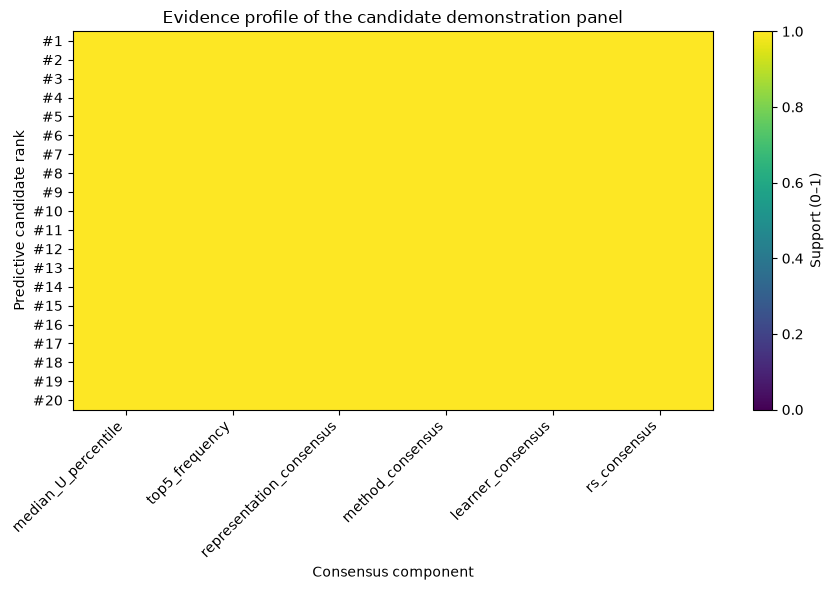

In [26]:
plot_cols = [
    "median_U_percentile",
    "top5_frequency",
    "representation_consensus",
    "method_consensus",
    "learner_consensus",
    "rs_consensus",
]

plot_data = (
    demonstration[
        [
            "predictive_rank",
            *plot_cols,
        ]
    ]
    .set_index(
        "predictive_rank"
    )
)

fig, ax = plt.subplots(
    figsize=(9.0, 6.0)
)

im = ax.imshow(
    plot_data.to_numpy(float),
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(
    np.arange(
        len(plot_cols)
    )
)
ax.set_xticklabels(
    plot_cols,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    np.arange(
        len(plot_data)
    )
)
ax.set_yticklabels(
    [
        f"#{int(x)}"
        for x in plot_data.index
    ]
)

ax.set_xlabel(
    "Consensus component"
)
ax.set_ylabel(
    "Predictive candidate rank"
)
ax.set_title(
    "Evidence profile of the candidate demonstration panel"
)

fig.colorbar(
    im,
    ax=ax,
    label="Support (0–1)",
)

plt.tight_layout()
plt.show()


# 25. How concentrated is candidate support?


In [27]:
tail_summary = pd.DataFrame(
    [
        {
            "n_eligible": len(
                eligible
            ),
            "median_predictive_consensus": (
                eligible[
                    "predictive_consensus_score"
                ].median()
            ),
            "q95_predictive_consensus": (
                eligible[
                    "predictive_consensus_score"
                ].quantile(
                    0.95
                )
            ),
            "top20_min_consensus": (
                demonstration[
                    "predictive_consensus_score"
                ].min()
                if len(
                    demonstration
                )
                else np.nan
            ),
            "top20_median_top5_frequency": (
                demonstration[
                    "top5_frequency"
                ].median()
                if len(
                    demonstration
                )
                else np.nan
            ),
            "top20_median_distinct_rs": (
                demonstration[
                    "n_distinct_rs"
                ].median()
                if len(
                    demonstration
                )
                else np.nan
            ),
            "top20_fraction_strict_R30_and_S30_support": (
                demonstration[
                    "strict_R30_and_S30_support"
                ].mean()
                if len(
                    demonstration
                )
                else np.nan
            ),
            "top20_fraction_exact_P_identity": (
                demonstration[
                    "exact_sequence_key_seen_as_P"
                ].mean()
                if len(
                    demonstration
                )
                else np.nan
            ),
        }
    ]
)

display(tail_summary)

,n_eligible,median_predictive_consensus,q95_predictive_consensus,top20_min_consensus,top20_median_top5_frequency,top20_median_distinct_rs,top20_fraction_strict_R30_and_S30_support,top20_fraction_exact_P_identity
0,101370,0.324749,0.738828,0.999479,1.0,5.0,0.7,0.0


# 26. RQ19 synthesis questions


After execution, RQ19 should answer:

1. How many broad-U proteins have sufficient factorial coverage to support robust prioritization?
2. How many distinct R×S cells does the typical eligible candidate appear in?
3. Are top candidates consistently high-ranked, or are they driven by isolated extreme scores?
4. How frequently do top candidates remain in tie-aware top-5% pools?
5. Do they remain candidate-like at S30?
6. Do they remain candidate-like at R30?
7. Is support shared by both T6 and T30?
8. Is support shared by both naive and BaggingPU?
9. Is support shared by LR and XGB?
10. Does one axis dominate each candidate's score, or are leave-one-component-out ranks stable?
11. Does EN broadly agree with the primary shortlist without being allowed to dominate it through clipping?
12. Which shortlisted proteins are also observed as U in conservative outer tests?
13. Do shared conservative-U candidates remain high-ranked there?
14. Are any nominal candidates exact-sequence duplicates of known positives?
15. Where sequences are available, are the candidates trivially close to known positives under a simple k-mer screening diagnostic?
16. Can Roxy descriptors be resolved for the shortlist?
17. If yes, do candidates occupy physicochemical ranges supported by positives?
18. Can T30 embeddings be resolved for the shortlist?
19. If yes, do candidates occupy positive-supported latent regions without requiring direct duplication?
20. Does an orthogonal-support augmented ranking strongly reshuffle the predictive top candidates?
21. Is there a small panel that remains strong across predictive, factorial, representation, paradigm, and learner axes?
22. Which evidence columns should accompany each candidate in the manuscript/SI so prioritization is auditable?
23. Which candidates should be excluded from a novelty demonstration because of exact positive identity?
24. Are there candidates that are predictively strong but orthogonally unusual, and therefore potentially interesting exploratory cases?
25. Can the final wording remain strictly “prioritized for experimental characterization” without implying validation?

The desired RQ19 output is a **transparent evidence-backed shortlist**, not a hidden scalar ranking.


## Manuscript-level interpretation targets

If a stable shortlist emerges:

> **A subset of unlabeled proteins remains consistently candidate-like across redundancy and homology regimes, both pretrained representations, two distinct PU formulations, and independent base learners. These proteins therefore represent robust candidates for experimental characterization rather than artifacts of a single model or permissive sequence split.**

If conservative and broad rankings agree for shared candidates:

> **Candidate support for pre-existing unlabeled proteins persists even when the biological scope of the unknown class is expanded, indicating that their prioritization is not solely a consequence of one U-universe definition.**

If orthogonal support is available:

> **The prioritized proteins occupy physicochemical and/or latent representation regions supported by known positives while remaining distinct unlabeled entities, providing orthogonal support for experimental follow-up without constituting functional validation.**

If orthogonal modules are unavailable:

> **Candidate prioritization remains supported by factorial predictive consensus, while physicochemical and latent-space characterization is explicitly left unclaimed because the required retained artifacts were not sufficiently resolvable.**


# 27. Export RQ19 cache tables


In [28]:
EXPORTS = {
    RQ19_CACHE / "rq19_score_schema_audit.tsv":
        score_schema_audit,
    RQ19_CACHE / "rq19_metadata_conflict_audit.tsv":
        metadata_conflict_audit,
    RQ19_CACHE / "rq19_primary_broad_U_evidence.tsv":
        primary_evidence,
    RQ19_CACHE / "rq19_candidate_consensus_all.tsv":
        candidate,
    RQ19_CACHE / "rq19_candidate_eligible_ranked.tsv":
        eligible,
    RQ19_CACHE / "rq19_predictive_shortlist_top100.tsv":
        predictive_shortlist,
    RQ19_CACHE / "rq19_candidate_factor_summary.tsv":
        candidate_factor_summary,
    RQ19_CACHE / "rq19_rank_stability.tsv":
        rank_stability,
    RQ19_CACHE / "rq19_rank_stability_summary.tsv":
        rank_stability_summary,
    RQ19_CACHE / "rq19_EN_candidate_diagnostic.tsv":
        en_candidate,
    RQ19_CACHE / "rq19_conservative_U_bridge.tsv":
        cons_bridge,
    RQ19_CACHE / "rq19_candidate_metadata_canonical.tsv":
        candidate_metadata,
    RQ19_CACHE / "rq19_identity_mapping_audit.tsv":
        identity_mapping_audit,
    RQ19_CACHE / "rq19_representation_contract_audit.tsv":
        representation_contract_audit,
    RQ19_CACHE / "rq19_roxy_feature_contract.tsv":
        roxy_schema.drop(
            columns=[
                "_feature_order_numeric",
            ],
            errors="ignore",
        ),
    RQ19_CACHE / "rq19_T30_feature_contract.tsv":
        pd.DataFrame(
            {
                "dimension_index": list(
                    range(
                        T30_EXPECTED_DIM
                    )
                ),
                "feature": T30_FEATURES,
            }
        ),
    RQ19_CACHE / "rq19_exact_positive_identity_audit.tsv":
        demonstration[
            [
                "sequence_key",
                "exact_sequence_key_seen_as_P",
            ]
        ],
    RQ19_CACHE / "rq19_sequence_relatedness.tsv":
        sequence_relatedness,
    RQ19_CACHE / "rq19_roxy_support.tsv":
        roxy_support,
    RQ19_CACHE / "rq19_T30_latent_support.tsv":
        latent_support,
    RQ19_CACHE / "rq19_demo_panel_overlap.tsv":
        demonstration_overlap,
    RQ19_CACHE / "rq19_final_demonstration_panel.tsv":
        final_demo,
    RQ19_CACHE / "rq19_tail_summary.tsv":
        tail_summary,
}

for path, frame in EXPORTS.items():
    if frame is None:
        continue

    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print(
    "Saved RQ19 cache tables:"
)

for path in EXPORTS:
    print(" ", path)

Saved RQ19 cache tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_score_schema_audit.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_metadata_conflict_audit.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_primary_broad_U_evidence.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_candidate_consensus_all.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_candidate_eligible_ranked.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19/rq19_predictive_shortlist_top100.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_

## Final guardrails before freezing RQ19

- `U` is unlabeled, never confirmed negative.
- A high-ranking U protein is not a confirmed lytic protein.
- Raw scores are not averaged across model families.
- Elkan–Noto does not receive a primary vote because clipping/ties can reduce upper-tail resolution.
- Top-tail membership is tie-inclusive.
- Candidate eligibility requires repeated factorial coverage.
- Failure to appear in conservative outer tests does not prove `U_other_unresolved` state.
- Exact positive-sequence identity must be exposed and excluded from a novelty demonstration.
- 5-mer Jaccard is a screening diagnostic, not homology or sequence identity.
- Roxy compatibility is not mechanistic evidence.
- T30 latent proximity is not functional validation.
- The support-augmented score is exploratory and must never hide its components.
- Missing physicochemical/latent artifacts are valid “not estimable” outcomes.
- No docking or mechanistic claims are required.
- Final wording: **prioritized for experimental characterization**.
